# 江苏永鼎股份有限公司（600105.SH）投资分析

**课程**：《证券投资学》　**专业**：大数据与财务管理　**班级**：25级大数据与财务管理03班
**姓名**：滕宇豪　**学号**：12607320270457　**指导教师**：李淑会

---

| 项目 | 内容 |
|---|---|
| 分析对象 | 江苏永鼎股份有限公司（600105.SH，上交所主板） |
| 所属行业 | 电气机械和器材制造业（证监会门类 C38）／光通信、汽车线束、海外电力工程、超导新材料 |
| 财务数据区间 | 2015—2025 年报 + 2026 年第三季度报告（分析主体取 2021—2026 近五年） |
| 行情数据区间 | 2016-01-04 — 2026-10-27（2615 个交易日） |
| 分析框架 | 宏观 → 行业 → 公司（素质 + 财务五维） → 估值 → 综合结论 |
| 数据底稿 | `data/raw`（原始）+ `data/processed`（派生），详见 `data/README.md` |
| 图表 | `figures/` 21 张 300dpi，全部由 `scripts/analysis_lib.py` 统一口径生成 |

> 本 Notebook 与 Word 报告共用同一套计算代码（`scripts/analysis_lib.py`），
> 因此文中任何一个数字都可以在此复现，不存在"报告一套数、底稿另一套数"的问题。


## 一、分析设计与数据底稿

### 1.1 为什么先讲数据

证券投资分析最容易出问题的地方不是模型，而是**数据的时点与口径**。本分析的三个关键处理：

1. **10 年底稿、5 年主体**。财务数据抓取 2016—2025 年报（含 2014、2015 供同比使用），
   行情抓 2016 年以来全部交易日。近五年（2021—2026）是分析主体，前五年（2016—2020）
   提供"上一轮周期"的参照——永鼎 2020 年巨亏 5.60 亿元、毛利率跌至 0.30%，
   如果没有这段历史，就无法判断 2026 年的 28.72% 毛利率究竟是"新常态"还是"周期高点"。
2. **TTM 按公告日生效，而不是按报告期**。市盈率的分母必须用"当时市场已经知道的利润"。
   若把 2026 年三季报的利润直接对齐到报告期末（9 月 30 日），则 8—9 月的 PE 会提前
   用到 10 月底才公开的数据，形成前视偏差，回测与估值判断都会系统性偏乐观。
3. **累计值必须拆成单季**。一季报/中报/三季报披露的是年初至期末累计数，
   要观察经营节奏（例如 2026 年单季营收是否逐季抬升），必须做差分。


In [1]:
import sys, os
sys.path.insert(0, "scripts")

import numpy as np
import pandas as pd
import analysis_lib as A

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.unicode.east_asian_width", True)

d = A.load_all()
print("年度比率表 ratios_annual      :", d["ra"].shape)
print("单季数据表 quarterly_single   :", d["single"].shape)
print("全期面板   panel_all_periods  :", d["panel"].shape)
print("分产品收入 segment_income     :", d["seg"].shape)
print("估值序列   valuation_daily    :", d["val"].shape,
      "|", d["val"]["日期"].min().date(), "→", d["val"]["日期"].max().date())
print("同业指标   peer_ind           :", d["peer_ind"].shape)
print("宏观序列   :", {k: len(v) for k, v in d["mac"].items()})


年度比率表 ratios_annual      : (11, 41)
单季数据表 quarterly_single   : (44, 20)
全期面板   panel_all_periods  : (44, 42)
分产品收入 segment_income     : (178, 6)
估值序列   valuation_daily    : (2615, 9) | 2016-01-04 → 2026-10-27
同业指标   peer_ind           : (477, 166)
宏观序列   : {'gdp': 51, 'cpi': 153, 'ppi': 153, 'pmi': 153, 'm2': 153, 'retail': 140, 'fai': 140, 'rrr': 23, 'lpr': 12}


### 1.2 三项口径校验

| 校验 | 做法 | 通过标准 |
|---|---|---|
| 单季拆分 | 各年 4 个单季营收加总 vs 年报营业收入 | 差异 < 0.01 亿元 |
| 杜邦恒等式 | ROE vs 净利率 × 总资产周转率 × 权益乘数 | 差异 < 2 个百分点 |
| 外部对照 | 最新 PE(TTM)、PB、市值 vs 腾讯财经实时快照 | 差异 < 0.5% |

第三项用抓取当日的快照（`data/raw/market/实时快照.json`，2026-10-27 16:14 收盘后）作为对照。
杜邦校验的容差之所以放宽到 2 个百分点，是因为分解式的权益乘数取**期末数**，
而 ROE 的口径用**平均净资产**，两者在权益大幅变动的年份（2020 年巨亏、2026 年高增长）
必然出现偏差——偏差本身也是"权益变动剧烈"的一个信号。


In [2]:
# 校验 1：单季营收加总 = 年报营收
q = d["single"].copy()
chk1 = (q.groupby("年度")["营业收入"].sum() / 1e8).rename("单季加总(亿元)").to_frame()
chk1["年报营收(亿元)"] = d["ra"].set_index("年度")["营业收入(亿元)"]
chk1["差异(亿元)"] = (chk1["单季加总(亿元)"] - chk1["年报营收(亿元)"]).round(4)
print("【校验1】单季拆分一致性")
print(chk1.round(3).to_string())

# 校验 2：杜邦恒等式
ra = d["ra"].set_index("年度")
chk2 = pd.DataFrame({
    "直接计算ROE%": ra["ROE%"],
    "杜邦分解ROE%": ra["杜邦校验ROE%"],
})
chk2["差异(pct)"] = (chk2["杜邦分解ROE%"] - chk2["直接计算ROE%"]).abs().round(3)
print("\n【校验2】杜邦恒等式（|差异| 应 < 2pct，权益乘数取期末值）")
print(chk2.round(3).to_string())


【校验1】单季拆分一致性
      单季加总(亿元)  年报营收(亿元)  差异(亿元)
年度                                            
2015          22.556          22.556        -0.0
2016          25.786          25.786         0.0
2017          28.713          28.713         0.0
2018          32.213          32.213         0.0
2019          33.710          33.710         0.0
2020          32.854          32.854         0.0
2021          39.097          39.097         0.0
2022          42.276          42.276         0.0
2023          43.451          43.451        -0.0
2024          41.112          41.112        -0.0
2025          52.868          52.868         0.0
2026          54.298             NaN         NaN

【校验2】杜邦恒等式（|差异| 应 < 2pct，权益乘数取期末值）
      直接计算ROE%  杜邦分解ROE%  差异(pct)
年度                                       
2015           NaN           NaN        NaN
2016        10.613        10.878      0.265
2017        11.024        11.473      0.450
2018         7.071         7.437      0.366
2019         0.786         0.84

In [3]:
# 校验 3：最新估值 vs 腾讯财经实时快照
import json
snap = json.load(open(os.path.join(A.RAW, "market", "实时快照.json"), encoding="utf-8"))
val = A.t_valuation(d).set_index("指标")["数值"]
print("【校验3】估值口径对外一致性（快照时间 %s）" % snap["抓取时间"][:19])
print(f"  本表 PE(TTM) = {val['PE(TTM)']:.2f}  |  快照 PE = {snap['PE_TTM']}")
print(f"  本表 PB      = {val['PB(MRQ)']:.2f}  |  快照 PB = {snap['PB']}")
print(f"  本表总市值   = {val['总市值(亿元)']:.2f} 亿元 |  快照总市值 = {snap['总市值(亿)']} 亿元")
print("  说明：PB 差异约 1.3%，源于分母净资产的取用报告期不同，不影响分位判断。")
print("\n完整估值表：")
print(A.t_valuation(d).to_string(index=False))


【校验3】估值口径对外一致性（快照时间 2026-10-27T23:22:07）
  本表 PE(TTM) = 57.13  |  快照 PE = 57.13
  本表 PB      = 9.55  |  快照 PB = 9.67
  本表总市值   = 369.88 亿元 |  快照总市值 = 369.88 亿元
  说明：PB 差异约 1.3%，源于分母净资产的取用报告期不同，不影响分位判断。

完整估值表：
               指标       数值                 说明
         收盘价(元)  25.300000           2026-10-27
       总股本(亿股)  14.619948         2026年三季报
       总市值(亿元) 369.884685        收盘价×总股本
TTM归母净利润(亿元)   6.474722        2025Q4—2026Q3
  TTM营业收入(亿元)  70.862718        2025Q4—2026Q3
            PE(TTM)  57.127501 总市值/TTM归母净利润
            PB(MRQ)   9.545898    总市值/归母净资产
            PS(TTM)   5.219736   总市值/TTM营业收入


## 二、宏观经济分析（2021—2026）

### 2.1 增长与价格：从"疫情冲击—修复"到"低通胀下的结构分化"

2016—2025 的十年，中国宏观走过了一轮完整的小周期：2017 年增速 6.9%、PPI 由负转正并冲高至 4.9%，
是典型的**主动补库存**；2020 年 GDP 增速骤降至 2.3%，2021 年在低基数与出口拉动下反弹至 8.6%，
PPI 更因大宗商品暴涨冲上 10.3%；2022 年起增速回落至 3.1%，随后 2023—2025 年稳定在 5.0% 附近。

价格信号比增速更能说明问题：**PPI 自 2022 年末起持续为负，2023—2025 年分别为
−2.7%、−2.3%、−1.9%**，CPI 长期在 0—1% 徘徊。这意味着制造业处于**"量增价减"**的环境——
营收可以靠出货量增长，但单价与毛利被持续压制。

对永鼎这样的中游制造企业，这一环境有两层含义：
- **压力**：光纤光缆、铜导体等标准化产品的价格随 PPI 下行，2023—2024 年公司毛利率虽从
  2022 年的 13.38% 回升至 17.30%，但 2025 年又回落至 13.89%，缺乏持续向上的价格支撑。
- **机会**：低利率 + 宽货币降低了制造业扩产与海外工程垫资的资金成本，同时 AI 算力投资
  带来的高端光纤需求，使**结构性涨价**（而非普涨）成为可能——这正是 2026 年毛利率跳升至
  28.72% 的宏观背景。

### 2.2 货币与景气：宽货币未转化为强景气

M2 增速 2022 年一度回升至 11.8%，2024 年回落到 7.3%，2025 年 8.5%，货币环境整体宽松；
但制造业 PMI 年均值自 2021 年的 50.54 一路下行至 2025 年的 49.57，**连续多年处于荣枯线下方**。
"宽货币 + 弱景气"的组合，决定了这轮行情不是全面复苏，而是**少数高景气赛道（AI 算力、
海风、电网投资）的结构性行情**——这也是理解光通信板块 2025—2026 年股价与业绩分化的关键。


In [4]:
A.t_macro_annual(d)


,GDP增速%,CPI同比%,PPI同比%,制造业PMI均值,M2同比%
年,,,,,
2016,6.8,2.1,5.5,50.32,11.30
2017,6.9,1.8,4.9,51.61,8.07
2018,6.8,1.9,0.9,50.90,8.10
2019,6.1,4.5,-0.5,49.73,8.70
2020,2.3,0.2,-0.4,49.92,10.10
2021,8.6,1.5,10.3,50.54,9.00
2022,3.1,1.8,-0.7,49.14,11.80
2023,5.4,-0.3,-2.7,49.89,9.70
2024,5.0,0.1,-2.3,49.78,7.30


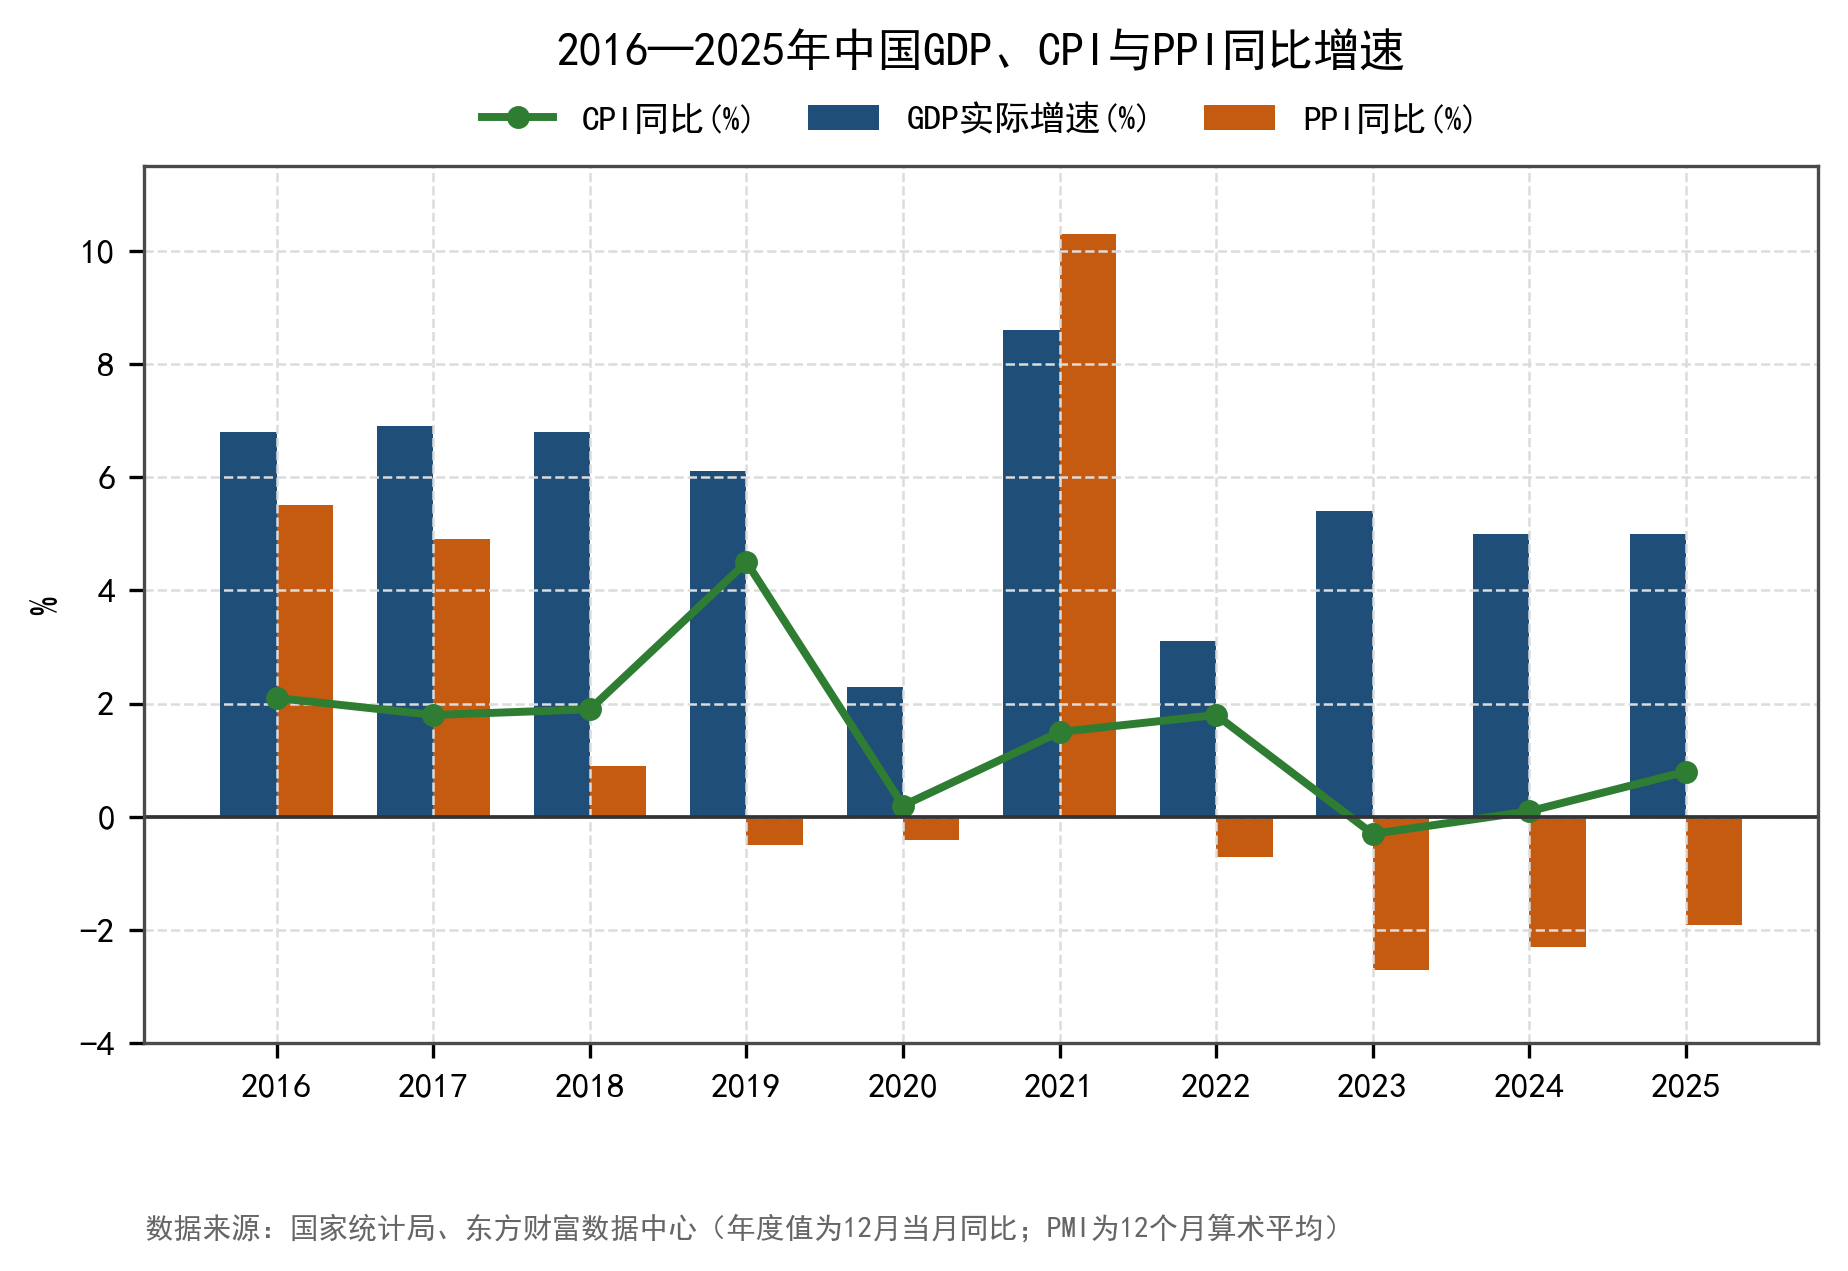

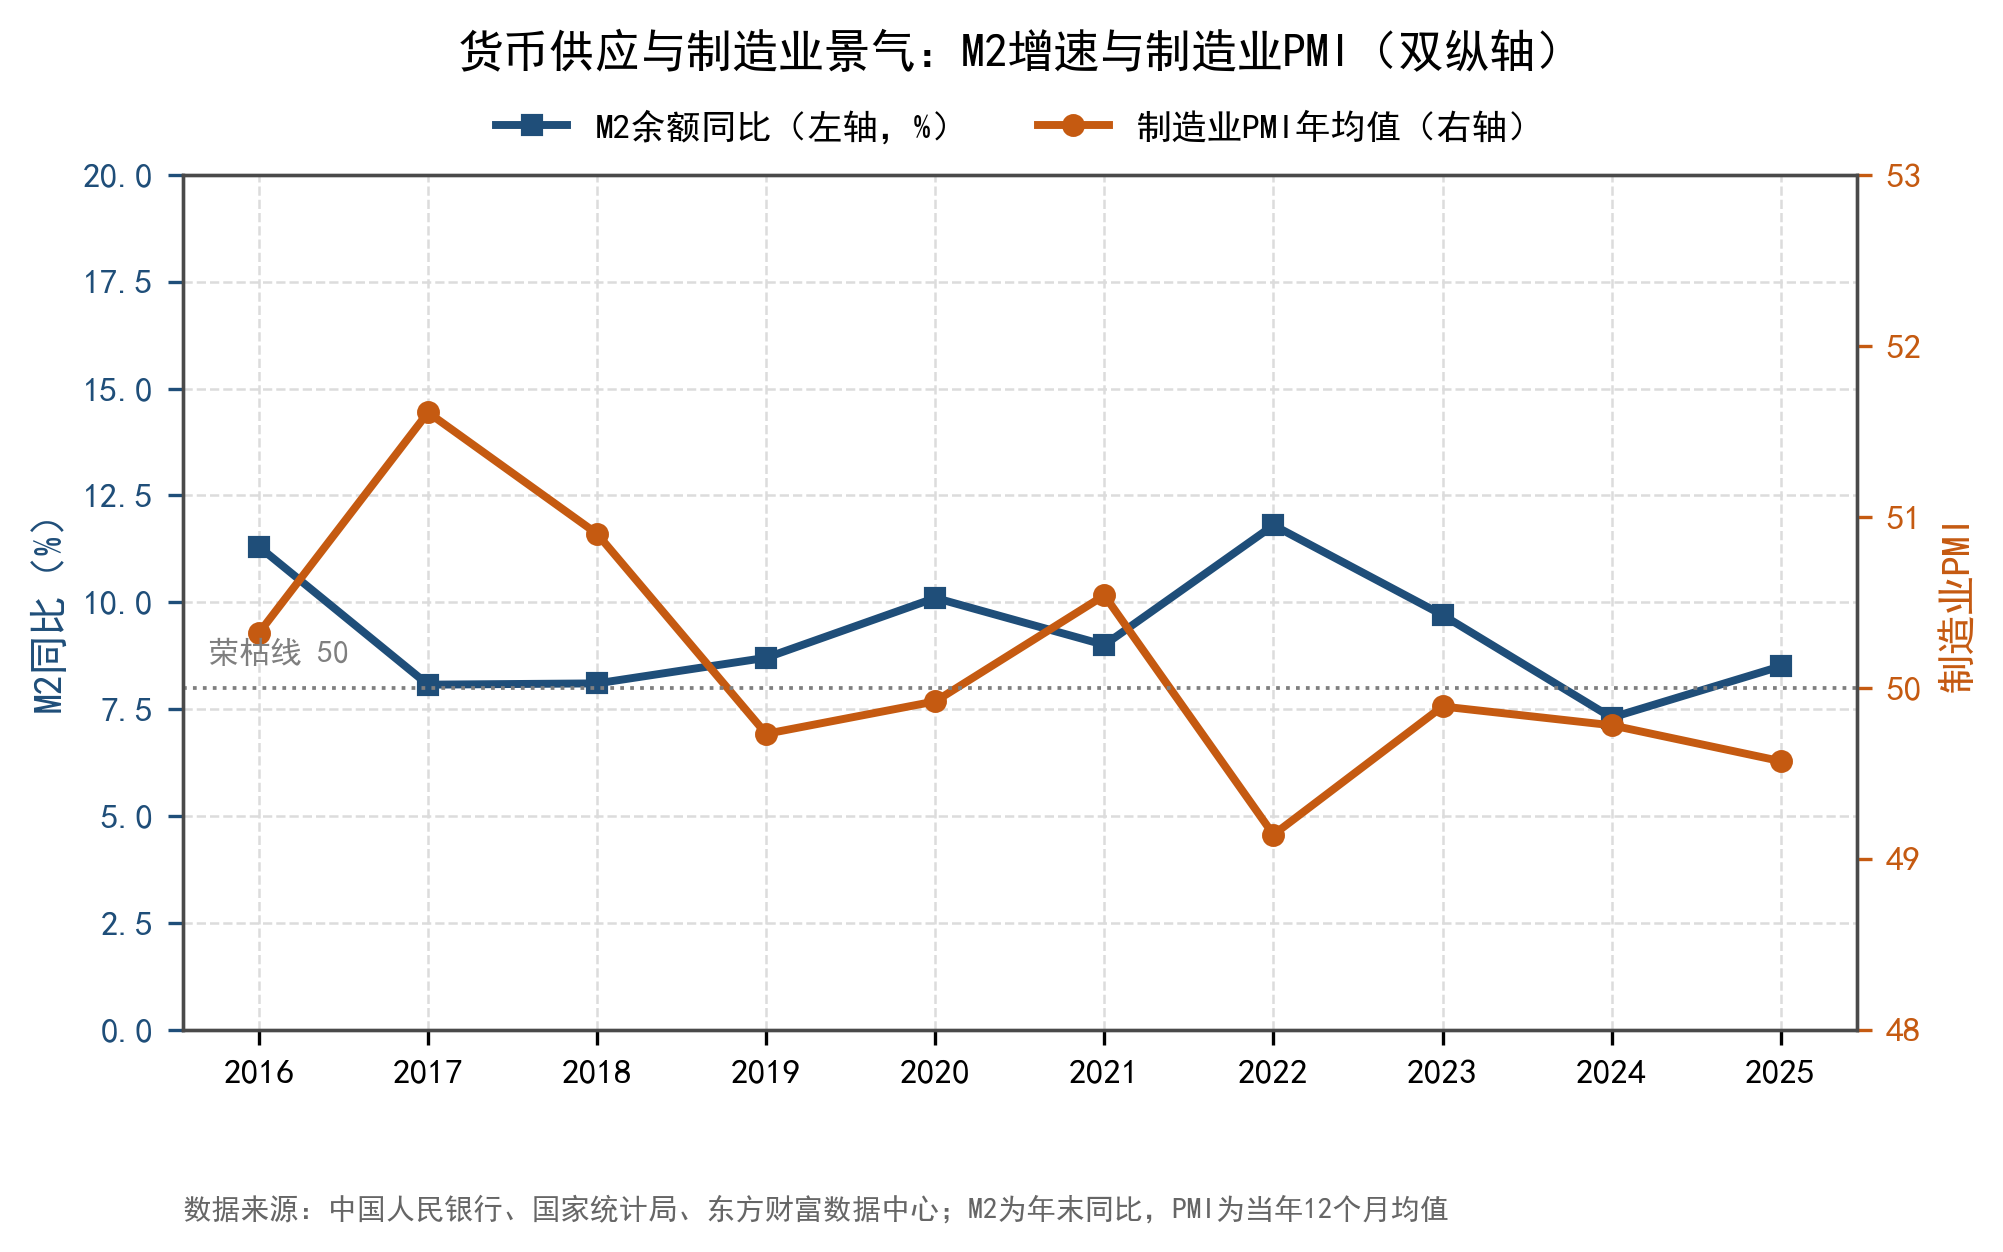

In [5]:
from IPython.display import Image, display
display(Image(filename=os.path.join(A.FIG, "图1-1_宏观GDP_CPI_PPI.png"), width=820))
display(Image(filename=os.path.join(A.FIG, "图1-2_宏观M2_PMI.png"), width=820))


## 三、行业分析

### 3.1 行业属性：成长赛道里的周期环节

永鼎的业务横跨四个差异极大的细分行业，不能用单一行业标签概括：

| 板块 | 行业属性 | 生命周期 | 2026H1 收入占比 | 2026H1 毛利率 |
|---|---|---|---|---|
| 光通信及光电缆 | 成长（AI 算力驱动）叠加周期（运营商集采） | 成长期—成熟期交界 | 约 36% | **58.5%** |
| 汽车线束 | 成长（新能源渗透） | 成长期 | 约 26% | 8.6% |
| 海外电力工程 | 周期 + 政策驱动（"一带一路"） | 成熟期 | 约 19% | 7.6% |
| 超导及铜导体 | 主题成长（超导）+ 纯加工（铜导体） | 导入期／成熟期 | 约 14% | 7.7% |

这解释了公司财务上最矛盾的现象：**营收体量最大的板块毛利极薄，利润几乎全部来自收入占比
三分之一的光通信**。2026H1 光通信毛利率 58.5%，而其余三个板块均在 8% 上下——
一条 8% 的汽车线束产线，需要约 7 倍的收入才能创造与光通信同等的毛利。

### 3.2 竞争格局：公司在两个赛道都是"第二梯队"

- **光纤光缆**：国内格局为"长飞—亨通—中天—烽火"四强主导，CR4 超过 60%，永鼎产能与份额
  均落后于第一梯队。但 2025 年以来 AI 数据中心对**多模光纤、空芯光纤、高密度光缆**的需求
  爆发，龙头的产能被高端订单占满，二线厂商得以进入供应链并获得溢价——这是永鼎光通信
  毛利率从 2021H1 的 8.2% 跃升至 2026H1 的 58.5% 的行业前提。
- **汽车线束**：外资（矢崎、住友、德尔福）与本土（昆山沪光、上海金亭等）并存，进入门槛在于
  整车厂认证周期（2—3 年），一旦定点则粘性强、但年降压力大（通常 3%—5%/年）。
  公司该板块毛利率从 2024H1 的 16.6% 降至 2026H1 的 8.6%，正是年降与铜价波动的直接结果。

### 3.3 政策与技术趋势

1. **AI 算力基建**："东数西算"与智算中心建设推动 400G/800G 光模块与新型光纤需求，
   是 2025—2026 年行业最强的边际变化。
2. **"双碳"与电网投资**：特高压、配网改造与海上风电送出，为电力工程与超导带材提供订单。
3. **超导材料**：公司是国内少数具备二代高温超导带材量产能力的企业之一，属于"主题期权"，
   当前收入体量小（2026H1 约 4.8 亿元，含铜导体），但对估值弹性的贡献不容忽视。

### 3.4 行业景气度研判

用同业的股价与营收两条线交叉验证景气度：股价反映预期，营收反映现实。


In [6]:
# 同业 2016 年以来股价累计涨幅（前复权，2016-01-04 = 100）
pp = d["peer_px"].copy()
px0 = d["px"].sort_values("日期")
own = px0.set_index("日期")["收盘"]

rows = []
for nm, g in pp.groupby("名称"):
    s = g.sort_values("日期").set_index("日期")["收盘"]
    rows.append((nm, s.iloc[0], s.iloc[-1], (s.iloc[-1] / s.iloc[0] - 1) * 100))
rows.append(("永鼎股份", own.iloc[0], own.iloc[-1], (own.iloc[-1] / own.iloc[0] - 1) * 100))
perf = pd.DataFrame(rows, columns=["名称", "期初收盘", "期末收盘", "区间涨幅%"]).sort_values("区间涨幅%", ascending=False)
print("2016-01-04 → 2026-10-27 区间涨幅（前复权）")
print(perf.round(2).to_string(index=False))


2016-01-04 → 2026-10-27 区间涨幅（前复权）
    名称  期初收盘  期末收盘  区间涨幅%
中际旭创      6.52    577.00    8755.13
长飞光纤     35.36    289.51     718.84
亨通光电      8.94     46.53     420.41
中天科技      6.91     25.85     274.26
永鼎股份      7.42     25.30     241.20
烽火通信     25.06     28.17      12.43
通鼎互联     17.27     14.72     -14.77


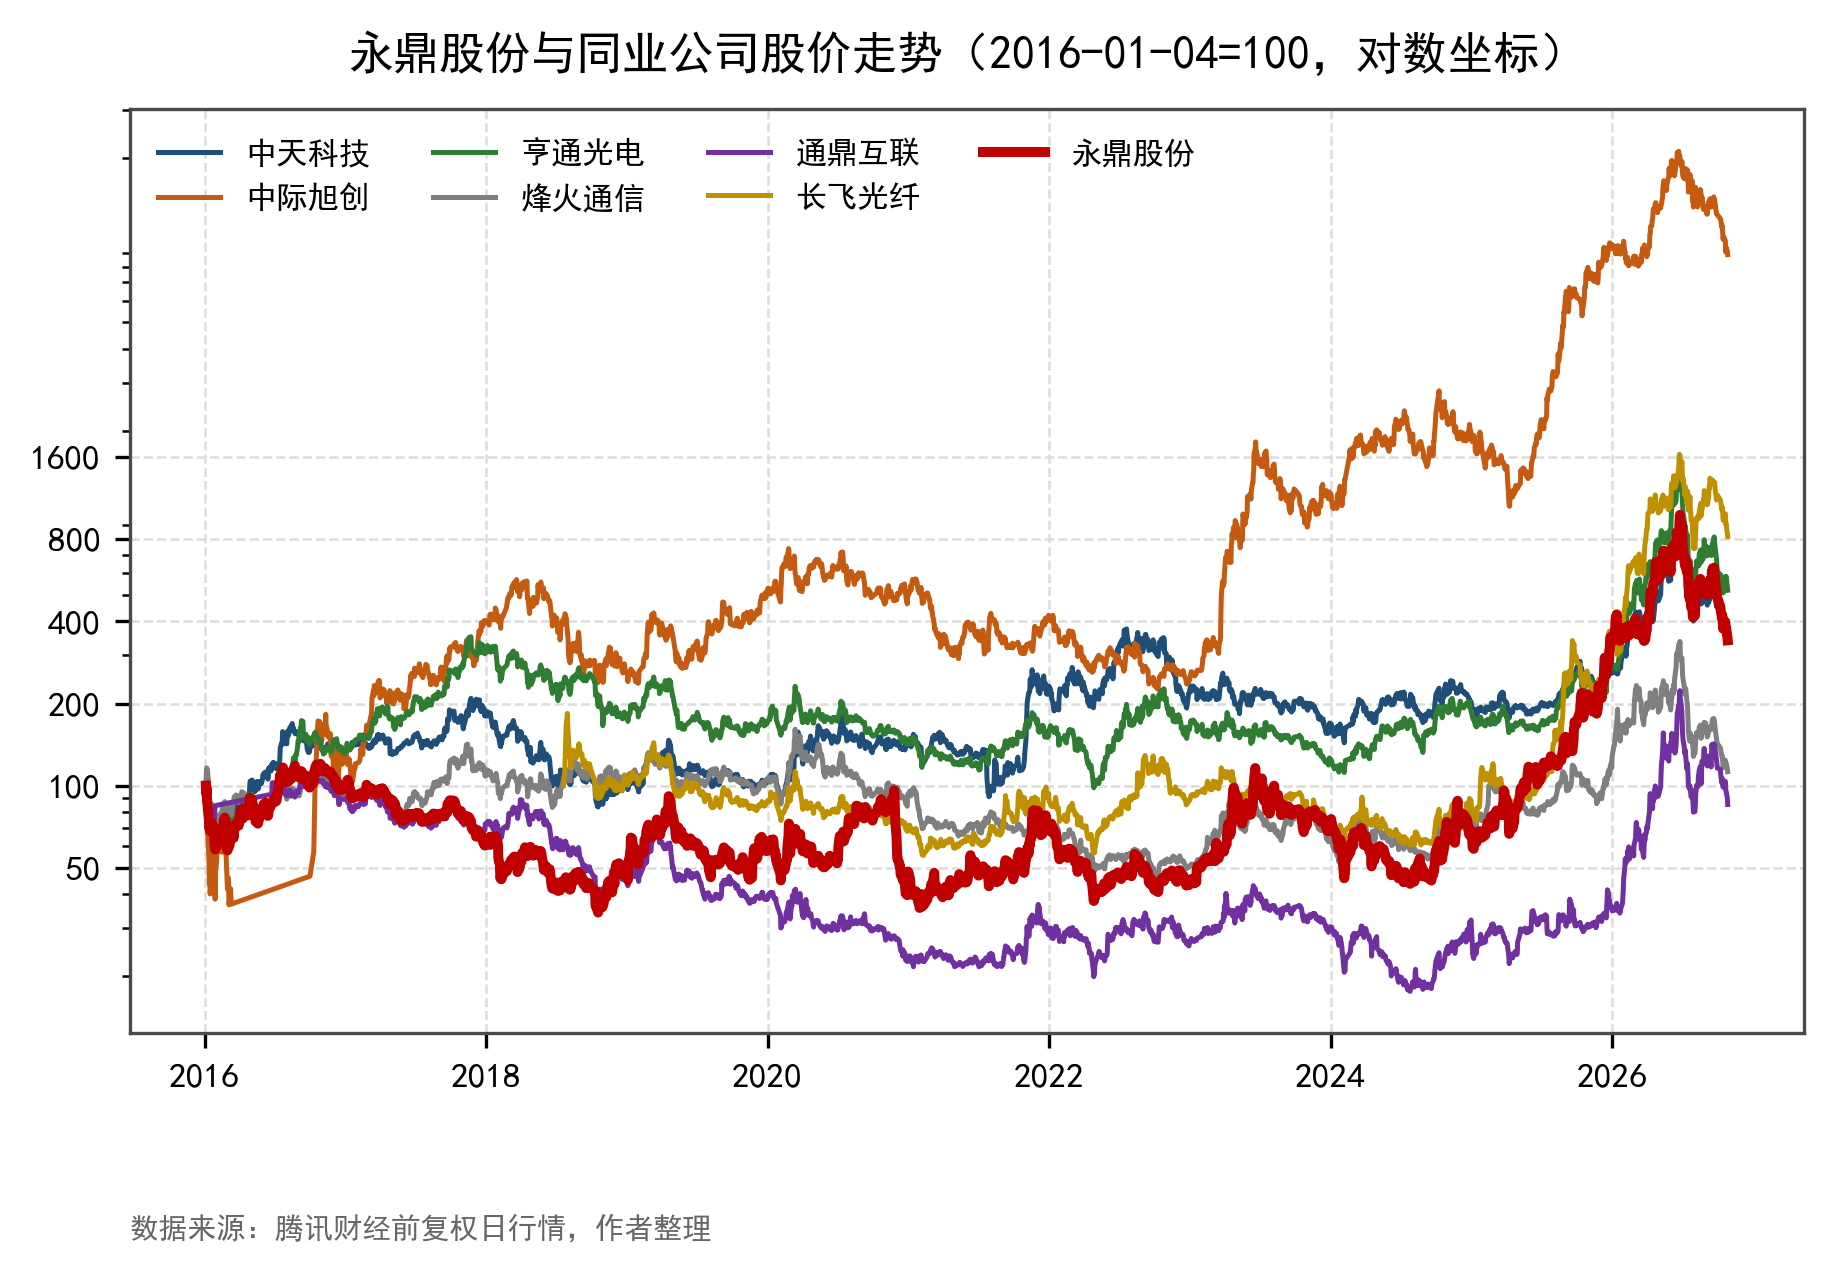

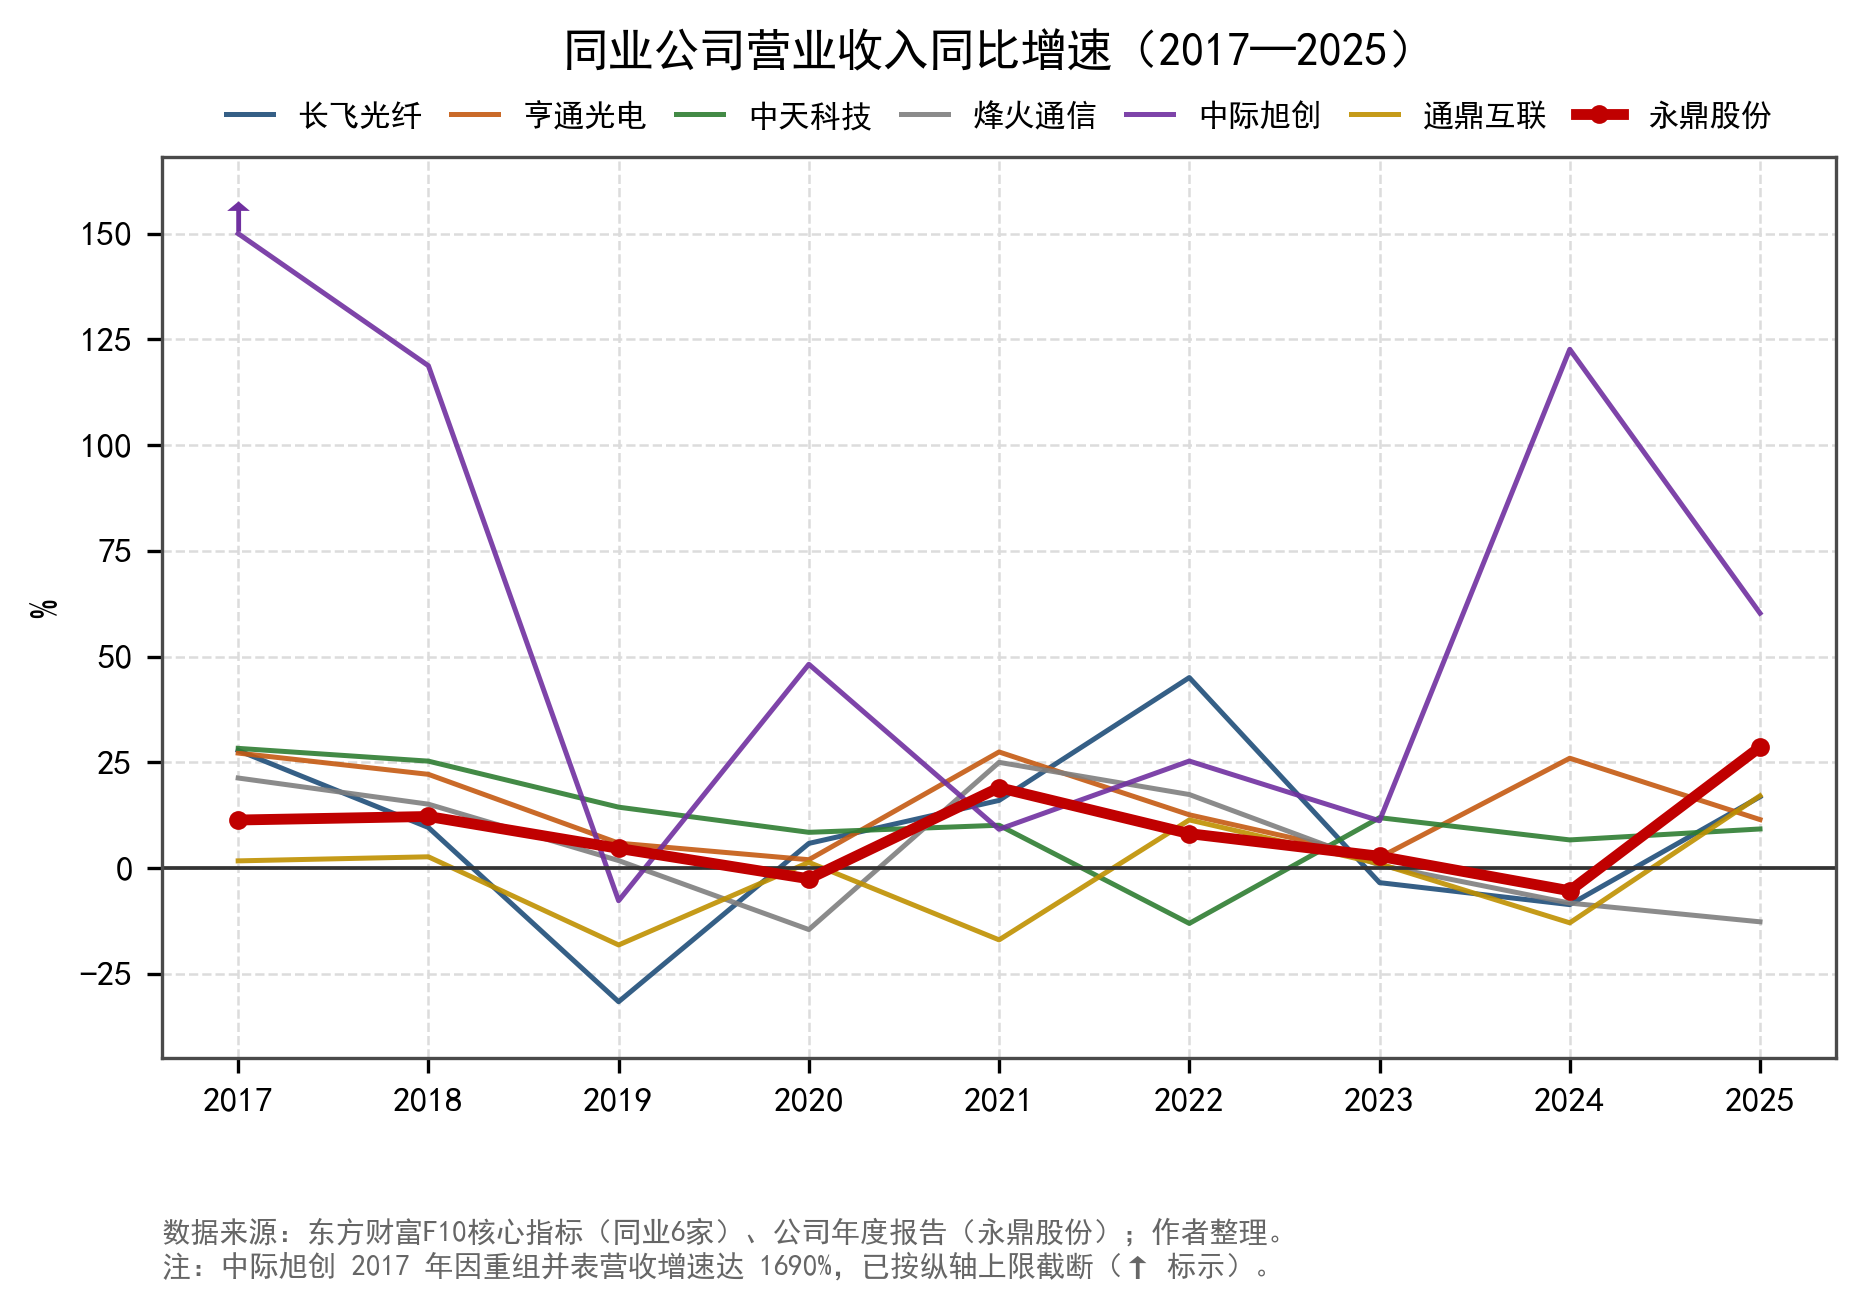

In [7]:
display(Image(filename=os.path.join(A.FIG, "图2-1_同业股价指数.png"), width=820))
display(Image(filename=os.path.join(A.FIG, "图2-2_同业营收增速.png"), width=820))


图 2-1 与图 2-2 给出的结论相当一致：**中际旭创是这一轮 AI 算力行情的最大受益者**，
2016 年初至 2026-10-27 区间涨幅约 **88 倍**；长飞光纤 +719%、亨通光电 +420%、中天科技 +274%，
永鼎股份 +241%，烽火通信仅 +12%，通鼎互联 −15%。
同为"光通信"，涨幅差距近 600 倍，说明市场定价的不是"行业"，而是**在产业链中的位置**。
营收端则更冷静：除中际旭创外，其余公司 2022 年以来增速普遍在 ±25% 区间震荡，
说明**行业总量的高增长已经结束，增长来自结构（高速率、高毛利产品）而非总量**。


In [8]:
# 分产品收入结构与毛利率（2021H1 起口径可比）
print("【分板块收入，亿元】")
print(A.t_segment_h1(d).loc["2021H1":].round(2).to_string())
print("\n【分板块毛利率，%】")
print(A.t_segment_margin_h1(d).loc["2021H1":].round(2).to_string())


【分板块收入，亿元】
板块    光通信  其他  大数据应用  汽车线束  电力工程  超导及铜导体
期                                                                
2021H1    5.25  0.22        0.54      5.66      7.92           NaN
2022H1    6.12  0.35        0.30      7.34      4.30           NaN
2023H1    5.84  0.53        0.20      6.75      5.45           NaN
2024H1    4.52  0.37        0.15      5.07      5.80          2.31
2025H1    4.02  0.53        0.13      7.63      6.77          3.51
2026H1   12.35  0.80        0.06      8.77      6.56          4.84

【分板块毛利率，%】
板块    光通信   其他  大数据应用  汽车线束  电力工程  超导及铜导体
期                                                                 
2021H1    8.15  29.51       32.29      7.56     13.26           NaN
2022H1   13.90  50.80       34.79      9.66     13.27           NaN
2023H1   10.38  47.58       44.66     13.57     16.38           NaN
2024H1   12.27  50.02       50.78     16.64     21.94         13.57
2025H1   19.50  38.21       85.14     13.77      9.55          7.81
2026H1   58.52  50.

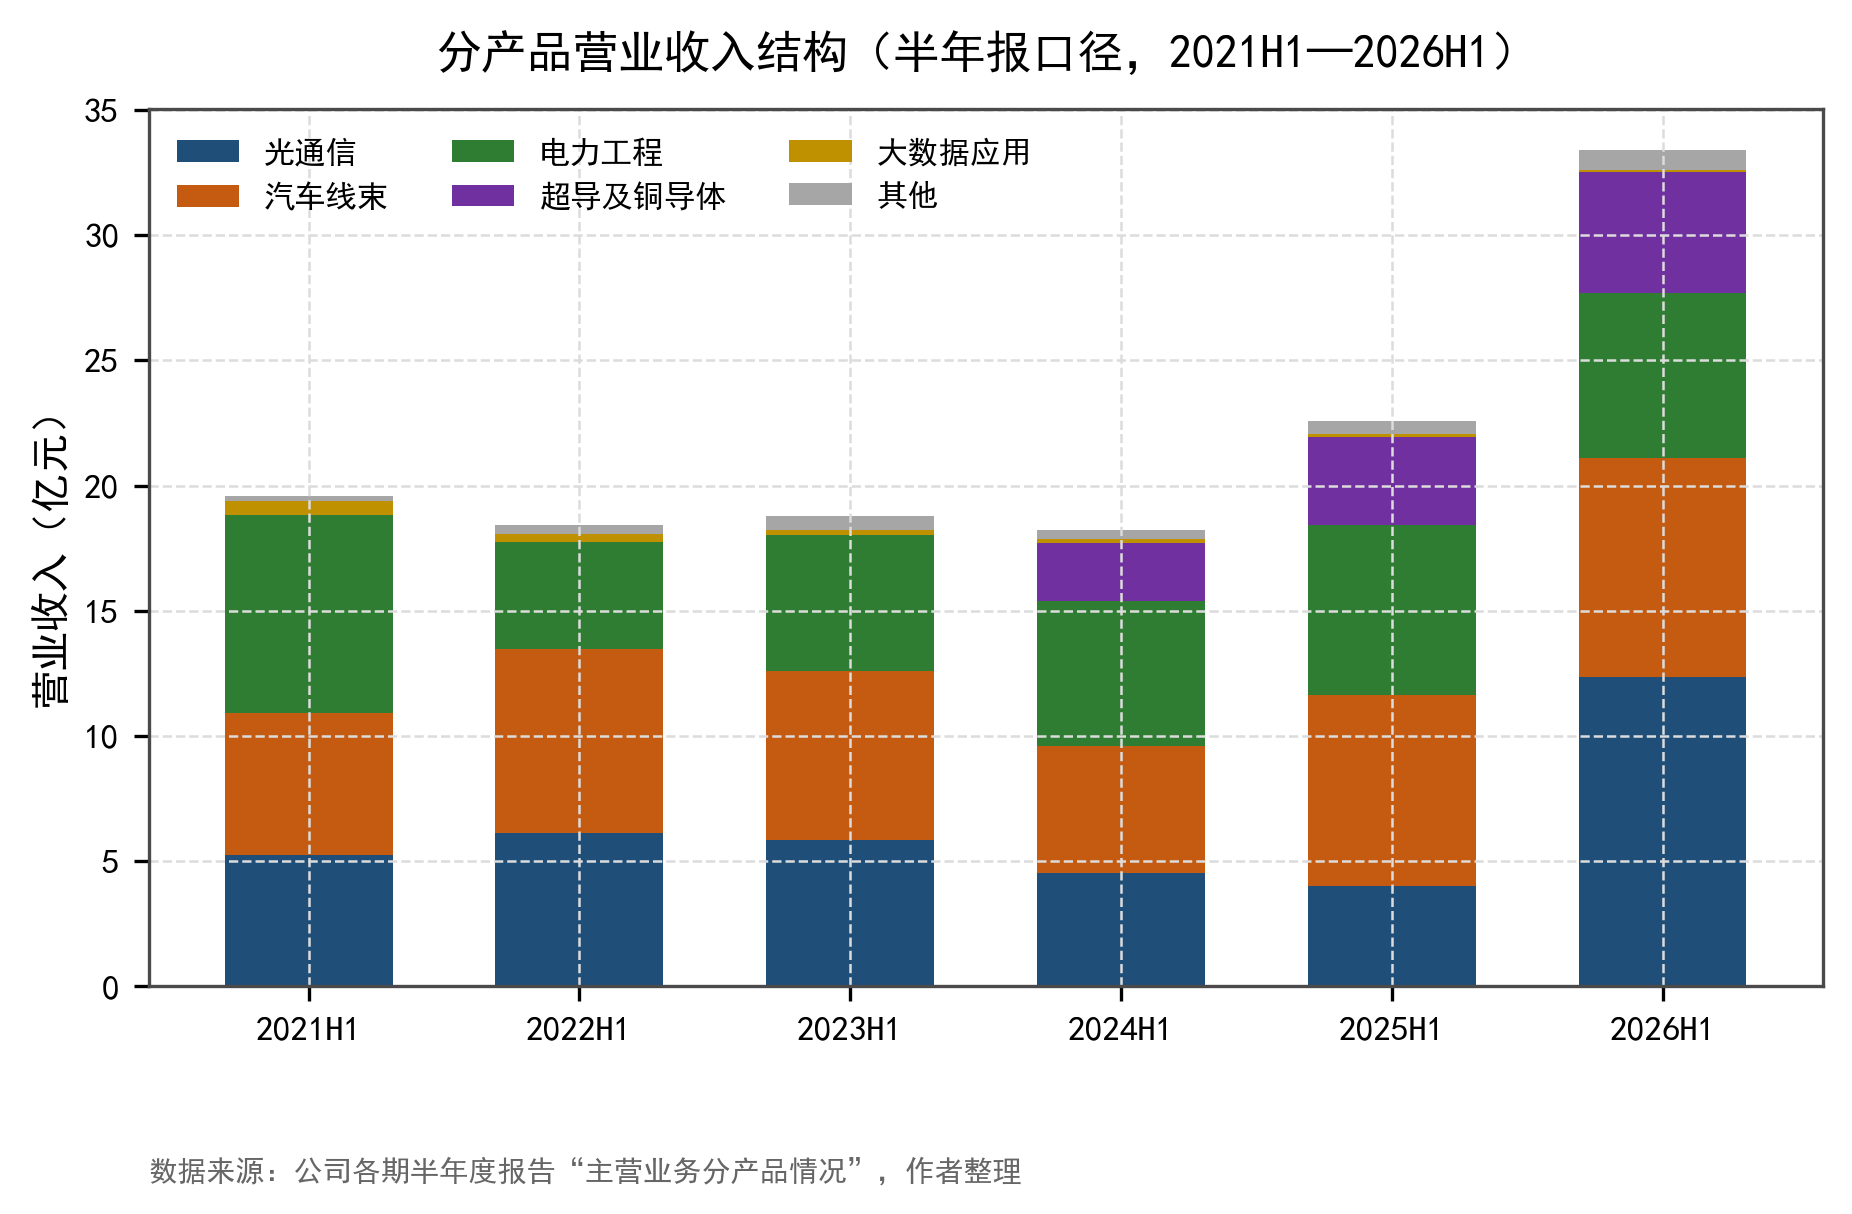

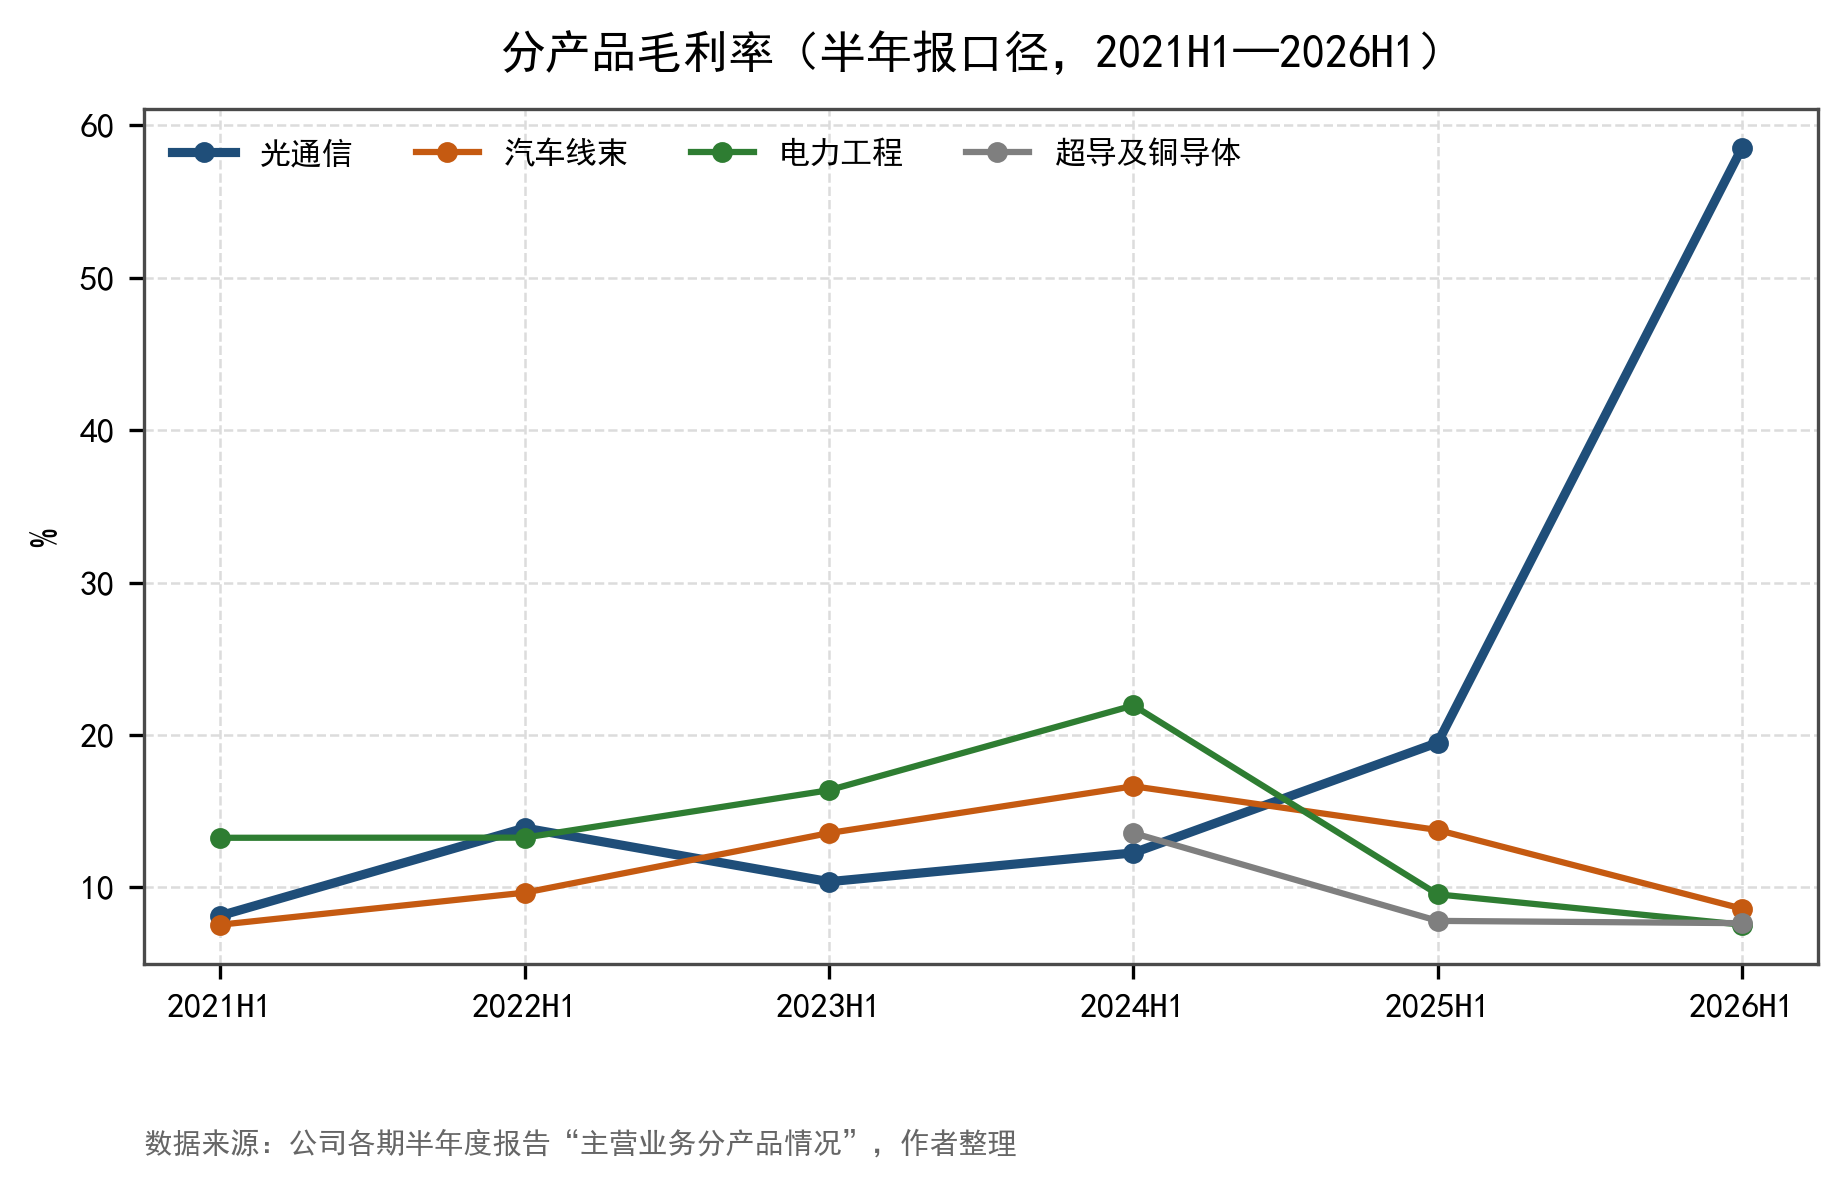

In [9]:
display(Image(filename=os.path.join(A.FIG, "图2-3_分产品收入结构.png"), width=820))
display(Image(filename=os.path.join(A.FIG, "图2-4_分产品毛利率.png"), width=820))


## 四、公司基本素质分析

### 4.1 主营业务与商业模式

公司成立于 1994 年，1997 年 9 月 29 日在上交所主板上市，总部位于江苏苏州吴江。
业务结构可概括为**"一体两翼"**：以光通信（光纤光缆、光棒、光模块、光器件）为主体，
以汽车线束（2015 年收购上海金亭）与海外电力工程（永鼎泰富）为两翼，超导材料为远期期权。

商业模式上，公司并非单一制造商，而是**"制造 + EPC 工程"混合体**：
海外电力工程采用 EPC/EPC+F 模式，收入确认按完工百分比，回款周期长（应收账款周转天数
显著高于纯制造企业），本币结算与美元结算并存，因而同时承担**信用风险与汇率风险**
（2025 年财务费用因人民币升值产生的汇兑损失即增加 3539.57 万元，同比增长 48.14%）。

### 4.2 竞争优势

1. **光通信全产业链**：具备"光棒—光纤—光缆—光器件—光模块"一体化能力，是国内少数能自供
   光棒的企业，成本控制与交付弹性优于纯拉丝厂。
2. **客户认证壁垒**：运营商集采与整车厂定点均需长周期认证，一旦进入则替换成本高。
   2025 年前五名客户销售占比 48.88%，客户集中度高既是风险也是"被验证"的信号。
3. **海外工程牌照与经验**：在东南亚、非洲、拉美等地区有十余年 EPC 积累，"一带一路"政策
   红利可直接转化为订单。
4. **超导先发优势**：二代高温超导带材国内玩家极少，具备主题稀缺性。

### 4.3 治理与管理层

公司为民营企业，实控人持股比例稳定，管理层长期由内部培养、产业经验丰富。
需要提示的是，公司历史上存在**非经常性损益对利润影响较大**的情况（2025 年尤为典型），
这要求分析者必须穿透到扣非口径，而不能只看归母净利润。

### 4.4 经营短板

- **盈利结构脆弱**：三个低毛利板块合计贡献约六成收入，却只贡献很小比例的毛利，
  一旦光通信景气回落，整体盈利会迅速塌陷（2023 年即为明证：毛利率 17.30%，净利率仅 1.00%）。
- **杠杆偏高**：资产负债率从 2016 年的 31.06% 升至 2026Q3 的 63.60%，短期借款由 2025 年末的
  22.6 亿元增至 2026Q3 的 29.8 亿元，长期借款由 8.9 亿元增至 11.9 亿元，财务费用刚性上升。
- **研发强度中等**：2025 年研发投入 3.10 亿元、占营收 5.86%，研发人员 605 人（占 17.56%），
  在光通信行业中不算突出，高端产品能否持续跟上龙头存在不确定性。


## 五、公司财务分析（2021—2026 为主体，2016 起纵向对照）

先看十年全表：营收从 2016 年的 25.79 亿元增至 2025 年的 52.87 亿元（CAGR 8.3%），
但归母净利润在 2 亿元上下反复，2020 年甚至亏损 5.60 亿元。**收入翻倍、利润原地踏步**，
是典型的"增收不增利"，也是分析这家公司必须回答的核心问题。


In [10]:
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("表 5-1 永鼎股份 2016—2025 年主要财务指标（2026 列为前三季度）")
A.t_annual(d)


表 5-1 永鼎股份 2016—2025 年主要财务指标（2026 列为前三季度）


年度,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026前三季度
指标,,,,,,,,,,,
营业收入(亿元),25.79,28.71,32.21,33.71,32.85,39.10,42.28,43.45,41.11,52.87,54.30
归母净利润(亿元),2.51,2.88,1.94,0.22,-5.60,1.21,2.14,0.43,0.61,2.34,7.43
扣非归母净利润(亿元),2.36,2.70,1.35,-0.22,-6.03,0.25,0.62,0.07,0.46,2.27,7.40
毛利率%,16.05,18.56,14.13,9.28,0.30,9.97,13.38,17.30,16.60,13.89,28.72
归母净利率%,9.72,10.04,6.01,0.64,-17.03,3.09,5.07,1.00,1.49,4.42,13.68
期间费用率%,NaN,13.43,13.71,13.41,15.99,13.03,13.00,14.81,15.82,14.28,13.32
ROE%,10.61,11.02,7.07,0.79,-20.56,4.35,7.61,1.54,2.08,7.45,15.80
ROA%,6.68,6.47,3.78,0.37,-8.23,1.63,2.83,0.54,0.74,2.70,5.41
流动比率,2.06,1.77,1.31,1.49,1.09,1.01,1.01,0.95,0.98,0.98,1.06


### 5.1 成长性：三段式，而非线性增长

| 阶段 | 期间 | 特征 | 归母净利润 |
|---|---|---|---|
| 平台期 | 2016—2019 | 营收 26→34 亿元，增速降至个位数；4G 建设尾声、光纤价格战开启 | 2.51→0.22 亿元 |
| 塌陷与修复 | 2020—2022 | 2020 年毛利率跌至 0.30%，叠加 2.20 亿元资产减值，巨亏 5.60 亿元；2021—2022 年修复 | −5.60→2.14 亿元 |
| 二次成长 | 2023—2026 | 2023—2024 年再度回落（0.43、0.61 亿元），2025 年靠投资收益回到 2.34 亿元，2026 年主业真正放量 | 0.43→7.43 亿元（前三季度） |

2026 年前三季度营收 54.30 亿元（同比 +49.6%）、归母净利润 7.43 亿元（同比 +125.8%），
**单年前三季度利润已是 2016—2025 任一完整年度的 2.6 倍以上**，且扣非占比 99.66%，
是十年来最"干净"的一次增长。

另一个必须点出的细节：2025 年前三季度归母净利润为 3.29 亿元，全年却只有 2.34 亿元，
说明**第四季度单季亏损 0.95 亿元**（当期计提资产减值 0.38 亿元、信用减值 0.18 亿元）。
年度数据会掩盖这种季内恶化，这正是做单季拆分的价值。


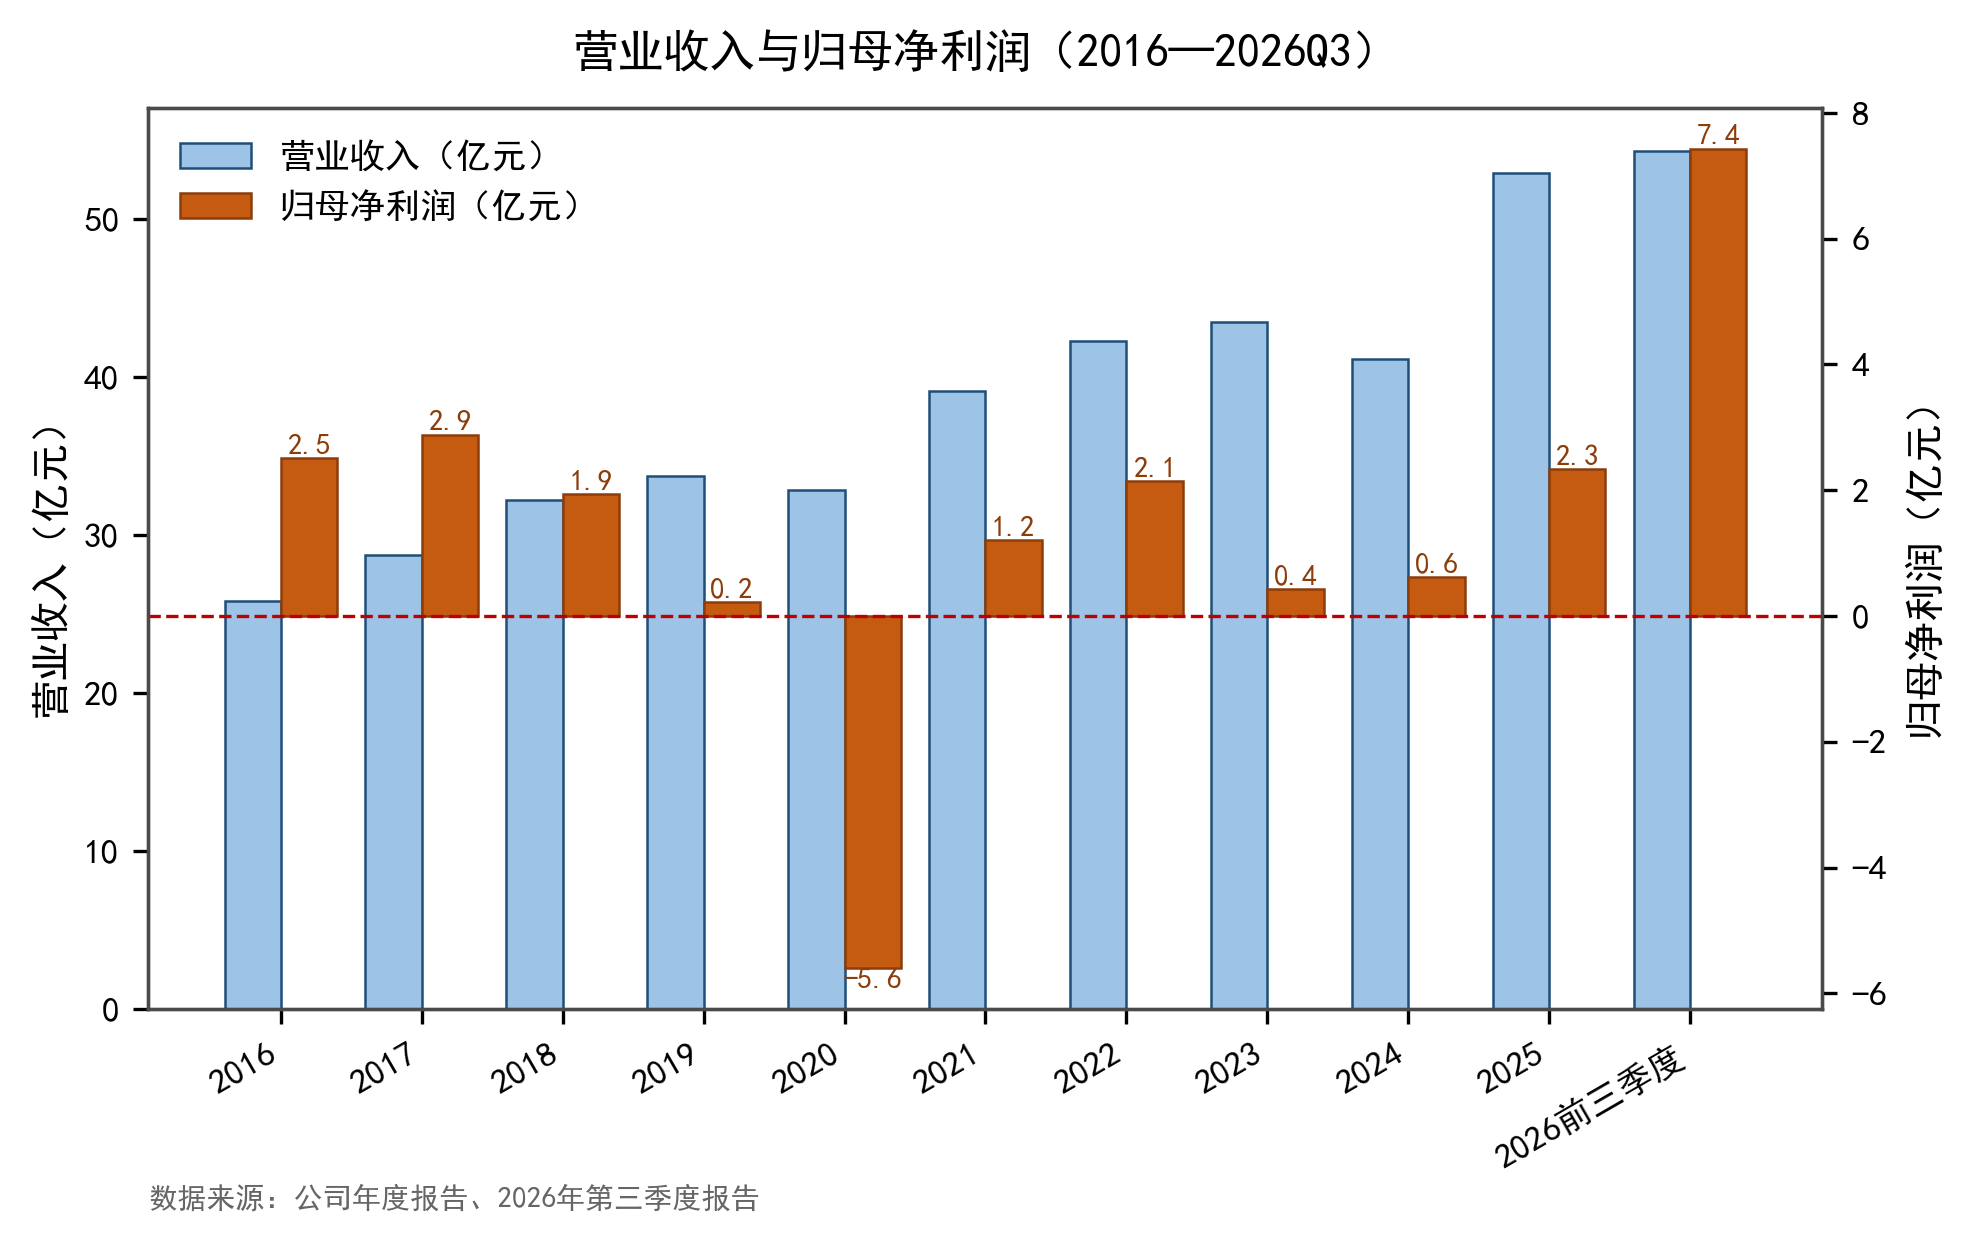

In [11]:
display(Image(filename=os.path.join(A.FIG, "图3-1_营收与归母净利.png"), width=820))


### 5.2 盈利能力：毛利率的"三级跳"与杜邦分解

毛利率的路径极不寻常：2017 年 18.56%（4G 建设高峰）→ 2020 年 0.30%（价格战与疫情双杀）
→ 2023 年 17.30%（修复）→ 2025 年 13.89%（回落）→ **2026 前三季度 28.72%**。
28.72% 不仅是十年最高，且高出历史峰值 10 个百分点以上，其可持续性是本报告最重要的判断点。

杜邦分解显示：ROE 的波动几乎完全由**净利率**驱动，总资产周转率十年稳定在 0.48—0.69 之间，
权益乘数则由 2016 年的 1.45 升至 2026Q3 的 2.75——**杠杆贡献了 ROE 中越来越大的部分**。
这意味着当前 15.80%（前三季度，年化约 21%）的 ROE 里，有相当比例来自"借来的钱"，
而非经营效率的提升。


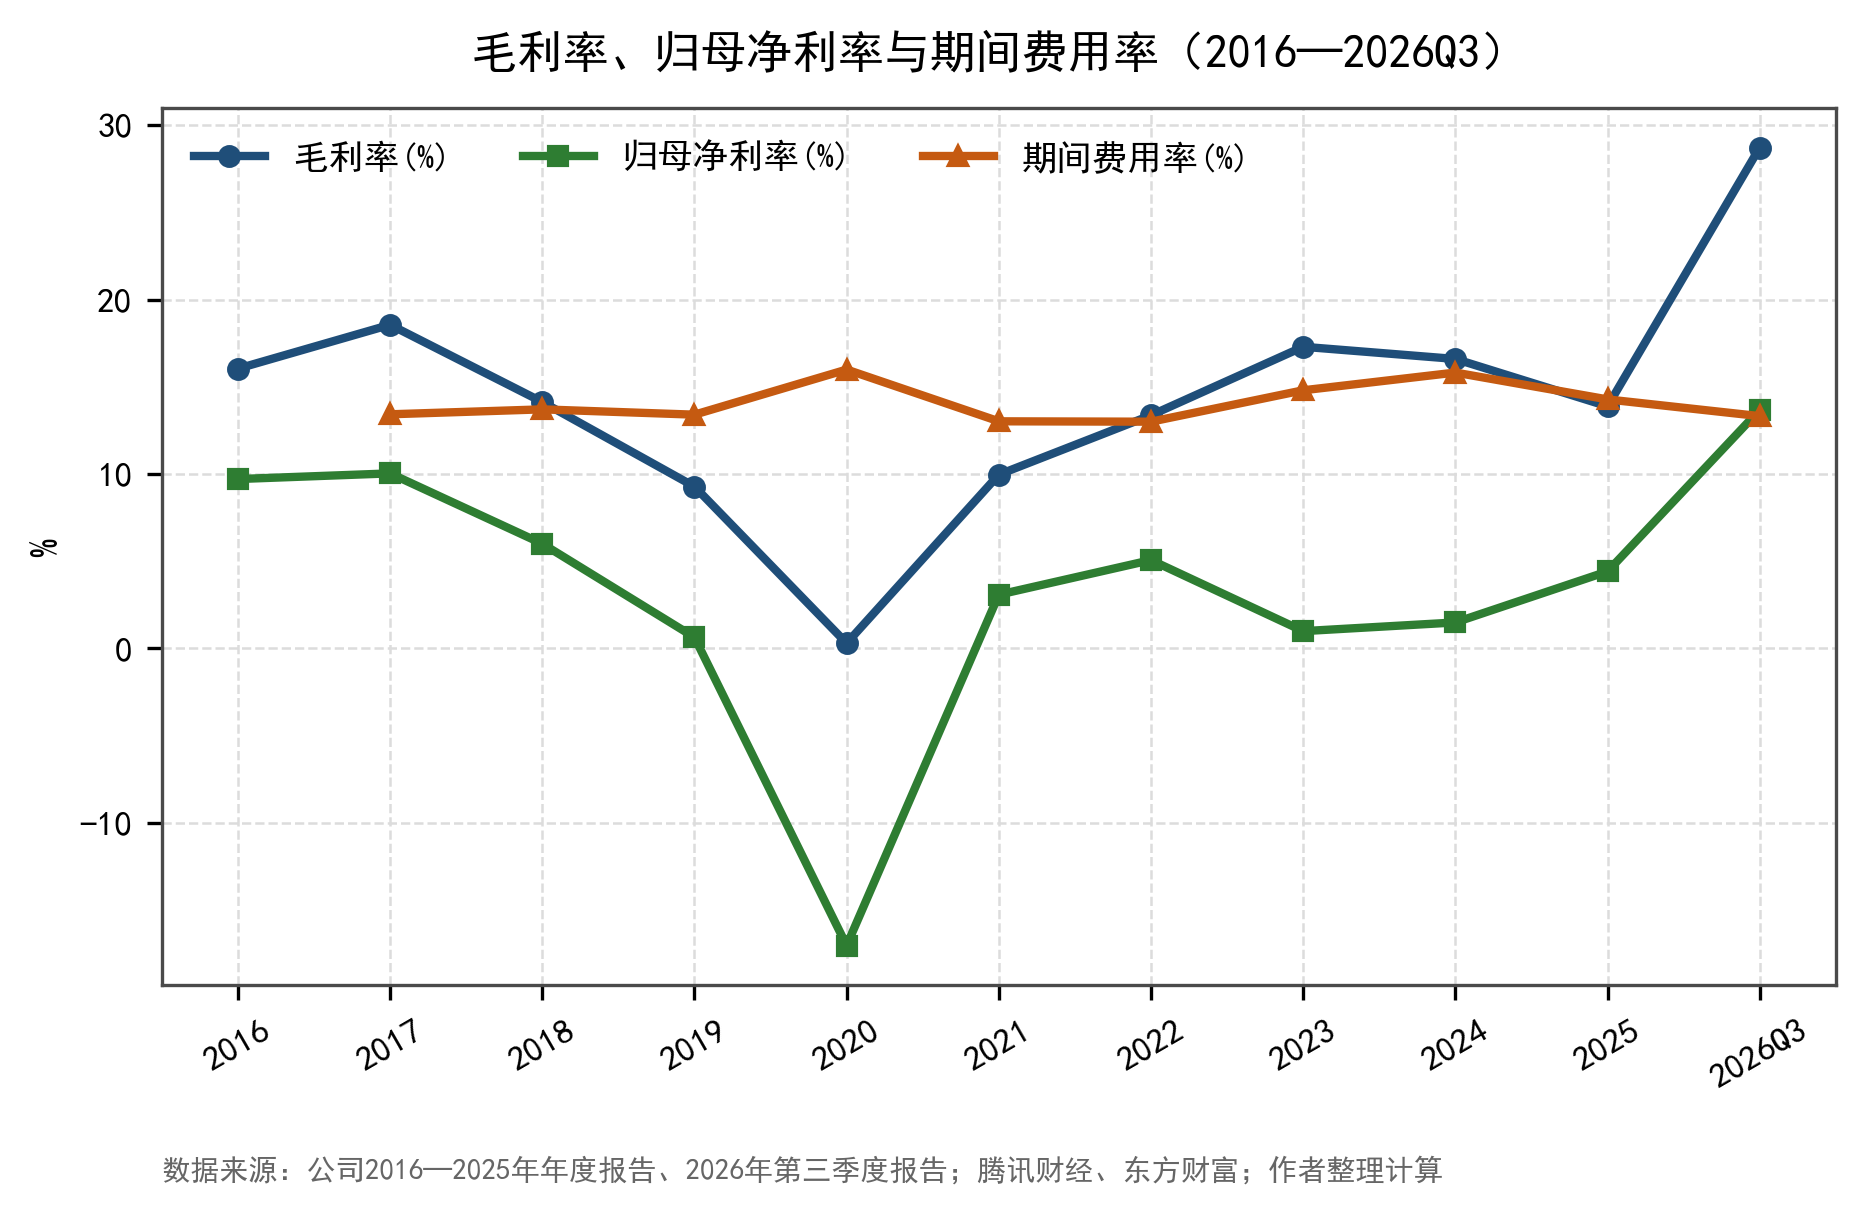

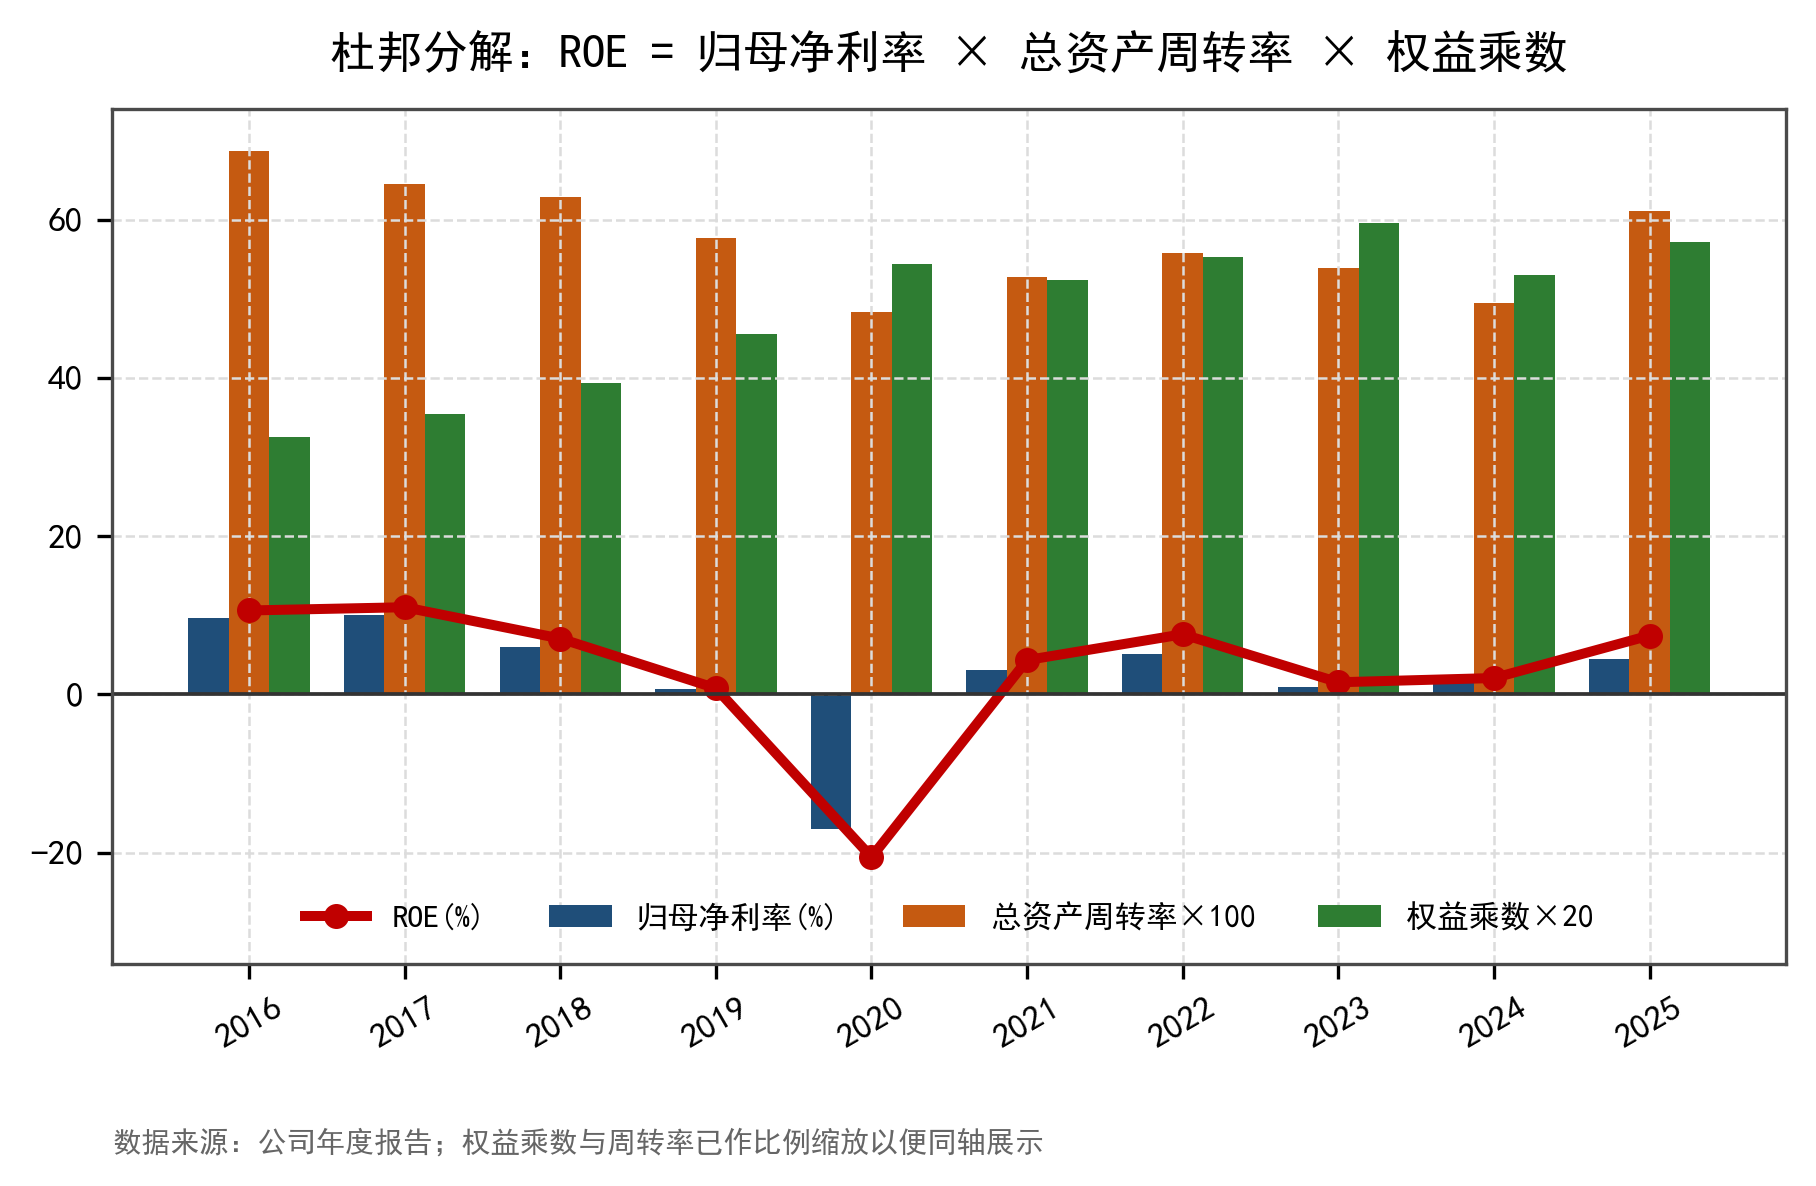

In [12]:
display(Image(filename=os.path.join(A.FIG, "图3-2_盈利能力指标.png"), width=820))
display(Image(filename=os.path.join(A.FIG, "图3-3_杜邦分解.png"), width=820))


In [13]:
# 杜邦三因子还原（近六年）
ra = d["ra"].set_index("年度")
dup = pd.DataFrame({
    "归母净利率%": ra["归母净利率%"],
    "总资产周转率": ra["总资产周转率"],
    "权益乘数": ra["权益乘数"],
    "ROE%(直接)": ra["ROE%"],
    "ROE%(三因子乘积)": ra["杜邦校验ROE%"],
}).loc[2019:]
q3 = d["q3"]
dup.loc["2026Q3(未年化)"] = [q3["归母净利率%"], q3["总资产周转率"], q3["权益乘数"], q3["ROE%"], np.nan]
print(dup.round(2).to_string())


                归母净利率%  总资产周转率  权益乘数  ROE%(直接)  ROE%(三因子乘积)
年度                                                                             
2019                   0.64          0.58      2.28        0.79              0.84
2020                 -17.03          0.48      2.72      -20.56            -22.38
2021                   3.09          0.53      2.62        4.35              4.27
2022                   5.07          0.56      2.76        7.61              7.81
2023                   1.00          0.54      2.98        1.54              1.60
2024                   1.49          0.50      2.65        2.08              1.96
2025                   4.42          0.61      2.86        7.45              7.72
2026Q3(未年化)        13.68          0.40      2.97       15.80               NaN


### 5.3 偿债能力：从"低杠杆"到"高杠杆"的十年

资产负债率 31.06%（2016）→ 63.60%（2026Q3），已经翻倍。流动比率从 2.06 降至 1.06，
速动比率 0.81，**短期偿债的安全垫基本耗尽**。更值得关注的是结构：
短期借款由 2025 年末的 22.60 亿元增至 2026Q3 的 29.85 亿元，长期借款由 8.90 亿元增至 11.88 亿元，
两项合计从 31.50 亿元扩张到 41.73 亿元，增量主要投向光通信扩产与海外工程垫资。

杠杆本身不是问题，问题在于**杠杆的成本与回报是否匹配**：
2025 年财务费用同比增长 48.14%（其中人民币升值带来的汇兑损失增加 3539.57 万元），
若光通信景气回落，利息支出将迅速侵蚀利润。


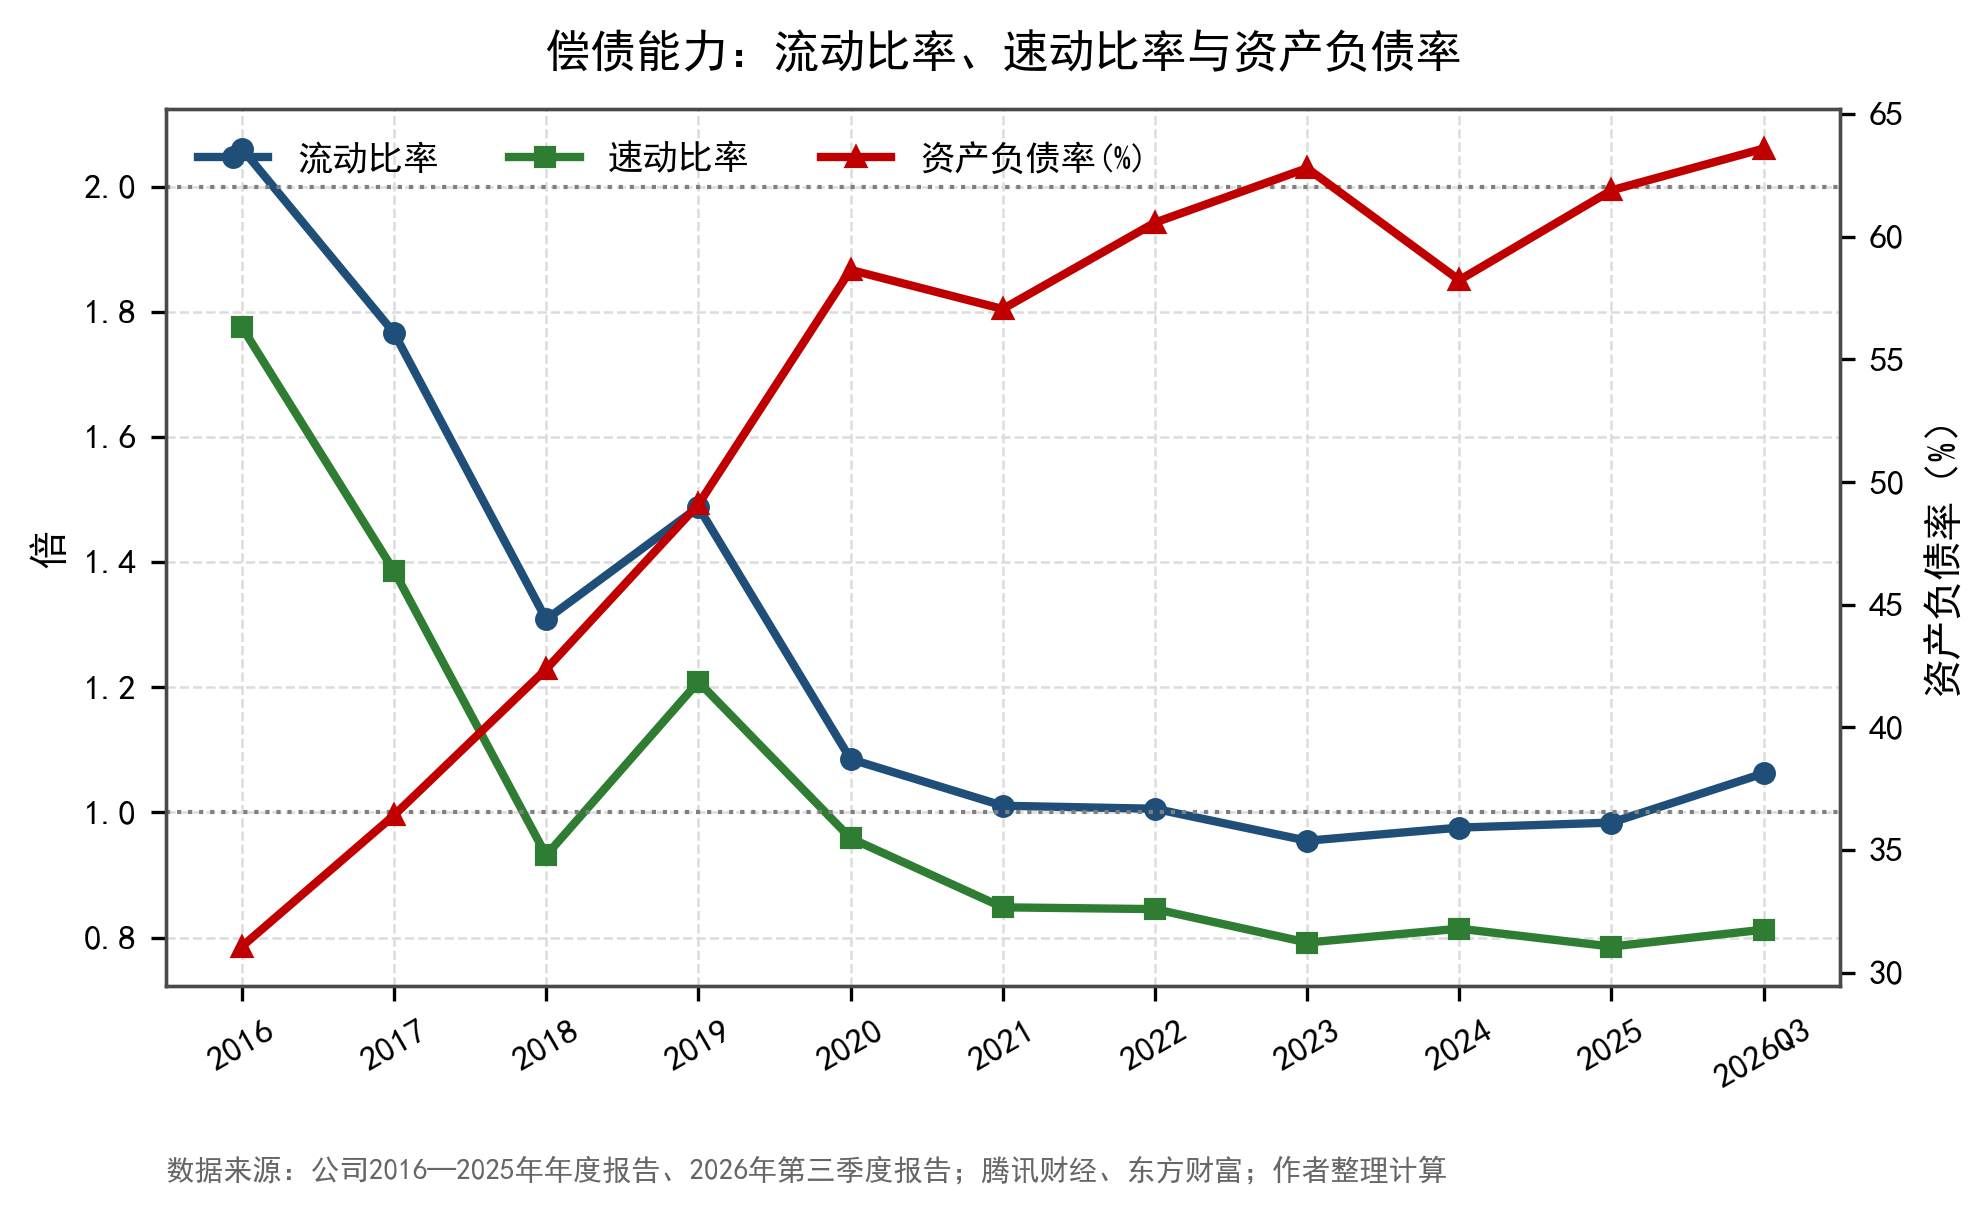

In [14]:
display(Image(filename=os.path.join(A.FIG, "图3-4_偿债能力.png"), width=820))


In [15]:
# 有息负债结构（期末余额，亿元）
p = d["panel"].copy()
p["期末"] = pd.to_datetime(p["REPORT_DATE"])
cols = [c for c in ["短期借款", "一年内到期的非流动负债", "长期借款", "应付债券"] if c in p.columns]
last = p.sort_values("期末").tail(6)[["报告期"] + cols].set_index("报告期")
last["有息负债合计"] = last.sum(axis=1)
print("【有息负债结构，亿元】")
print((last / 1e8).round(2).to_string())


【有息负债结构，亿元】
            短期借款  长期借款  应付债券  有息负债合计
报告期                                                
2025中报       24.70      6.93       NaN         31.63
2025三季报     24.43      8.63       NaN         33.06
2025年报       22.60      8.90       NaN         31.50
2026一季报     25.79      9.60       NaN         35.39
2026中报       26.57     11.39       NaN         37.96
2026三季报     29.85     11.88       NaN         41.73


### 5.4 营运能力：应收与存货是两把尺子

应收账款周转率从 2016 年的 3.55 次降至 2026 前三季度的 2.42 次，存货周转率 5.85→2.46
（后两者为前三季度口径，与年度口径不完全可比，但方向明确）。两项同时走弱，
与"海外 EPC 回款慢 + 光通信备货增加"的业务逻辑一致：
**收入增长越快，占用的营运资金越多**，这也是有息负债快速扩张的直接原因。

一个容易被忽略的细节：固定资产周转率在 2021—2025 年持续下滑，
说明前期扩产的产能利用率尚未完全释放，2026 年的收入放量正在修复这一指标。


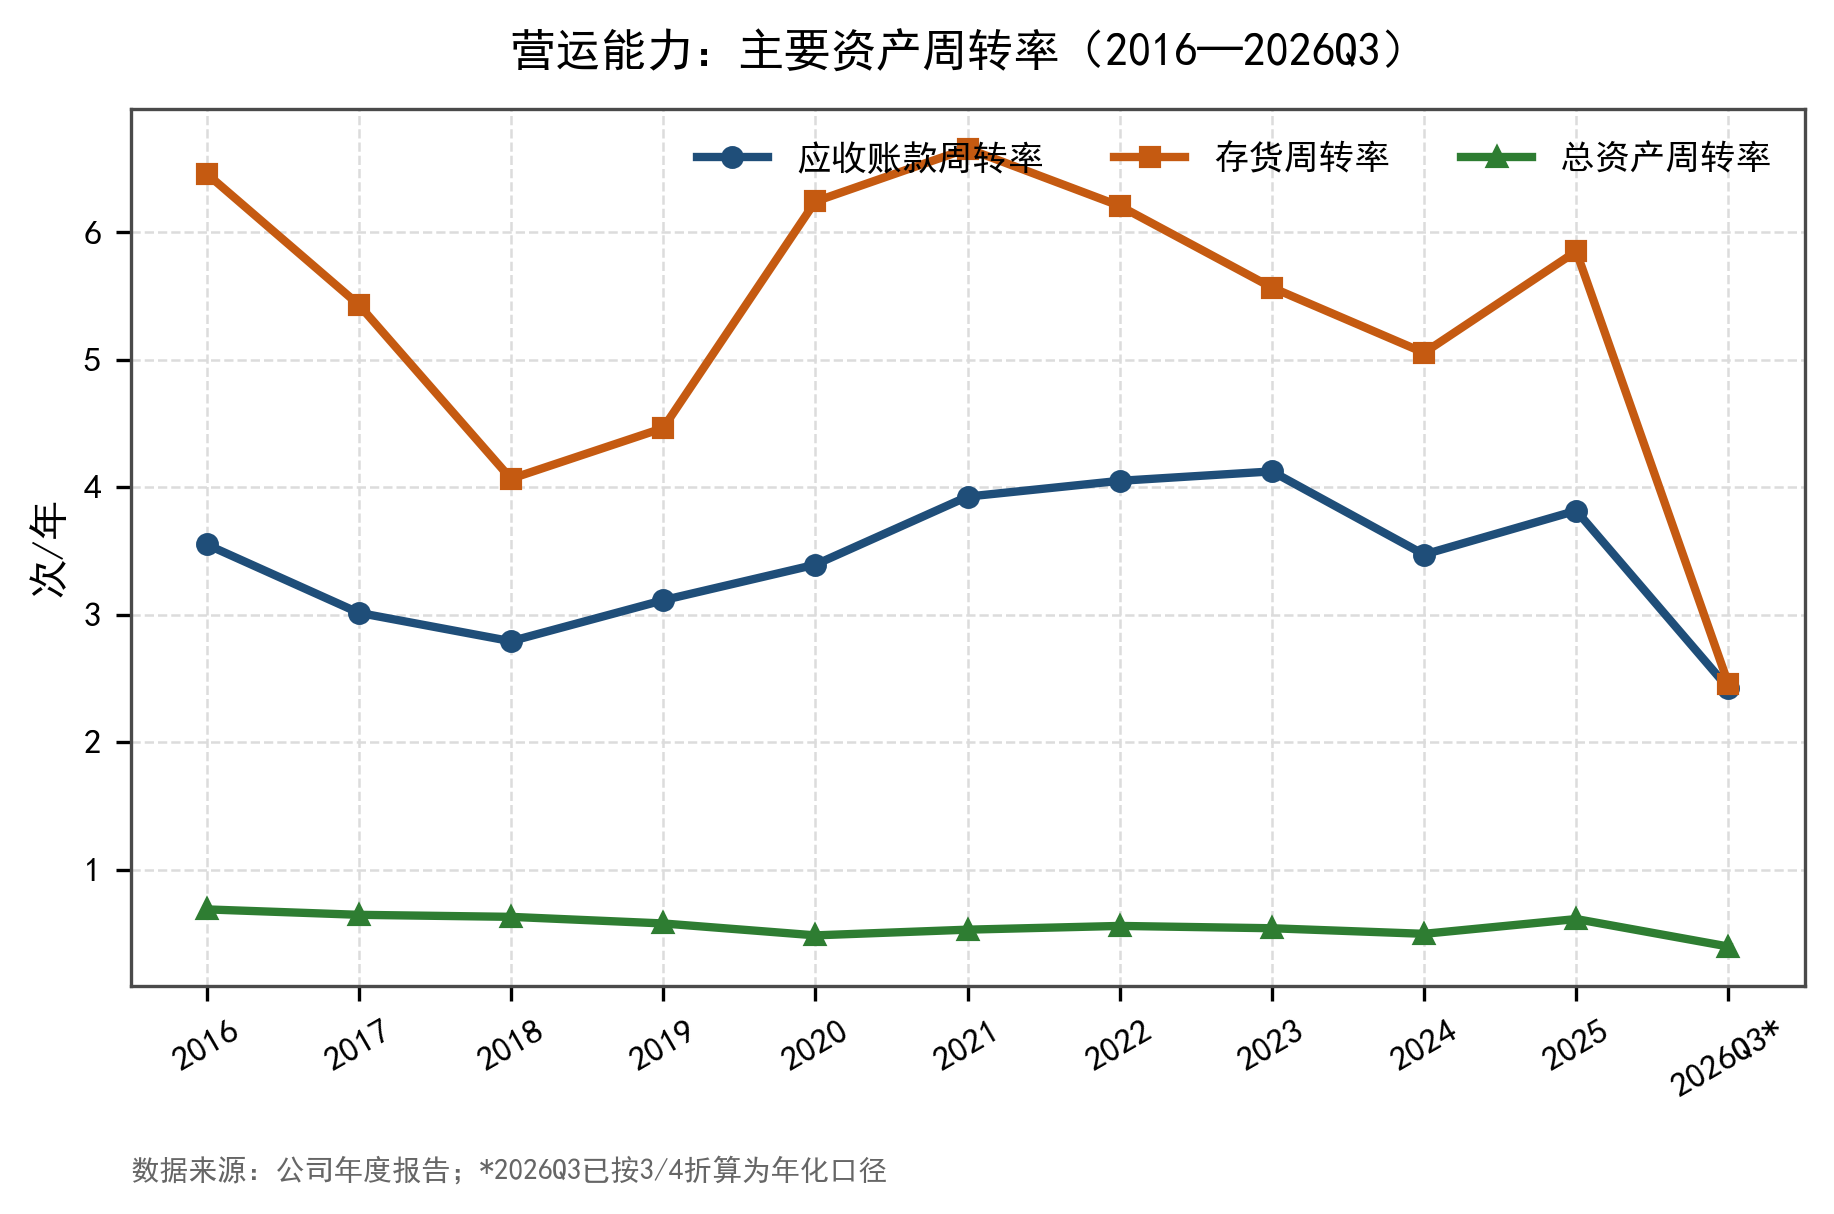

In [16]:
display(Image(filename=os.path.join(A.FIG, "图3-5_营运能力.png"), width=820))


### 5.5 现金流量与盈利质量：本报告最关键的发现

现金流三项净额在十年间频繁异号：经营活动现金流净额有 5 年为负，
2023 年净现比高达 6.64（因为净利润极低而非现金流好），2024 年为 −5.47。
**净现比长期大幅波动，说明利润的"含金量"不稳定**。

2025 年是最需要拆解的一年。归母净利润 2.34 亿元看似是 2024 年（0.61 亿元）的近 4 倍，
但拆开看：

| 项目 | 金额（亿元） | 说明 |
|---|---|---|
| 毛利 | 7.34 | 营收 52.87 × 毛利率 13.89% |
| 减：期间费用 | −7.55 | 销售+管理+研发+财务 |
| **＝主业经营利润** | **−0.21** | **主业实际亏损** |
| 加：投资收益 | +2.87 | 其中对联营企业东昌投资权益法确认 **2.74 亿元**，源自其房地产业务处置项目子公司 |
| 加：其他收益及减值等 | −0.18 | |
| ＝营业利润 | 2.23 | |

也就是说，**2025 年的利润几乎全部来自一项与主业无关、且不可持续的房地产处置收益**。
扣非归母净利润仅 2.27 亿元，扣非占比虽达 97.10%（因为投资收益按权益法计入经常性损益），
但性质上仍属一次性。若以 2025 年"净利大增"为前提给公司估值，会严重高估其盈利能力。

相比之下，**2026 年前三季度是完全不同的故事**：投资收益仅 0.12 亿元，扣非 7.40 亿元、
占归母 99.66%，毛利率 28.72%、净利率 13.68%——这是十年来第一次由主业真实驱动的盈利。


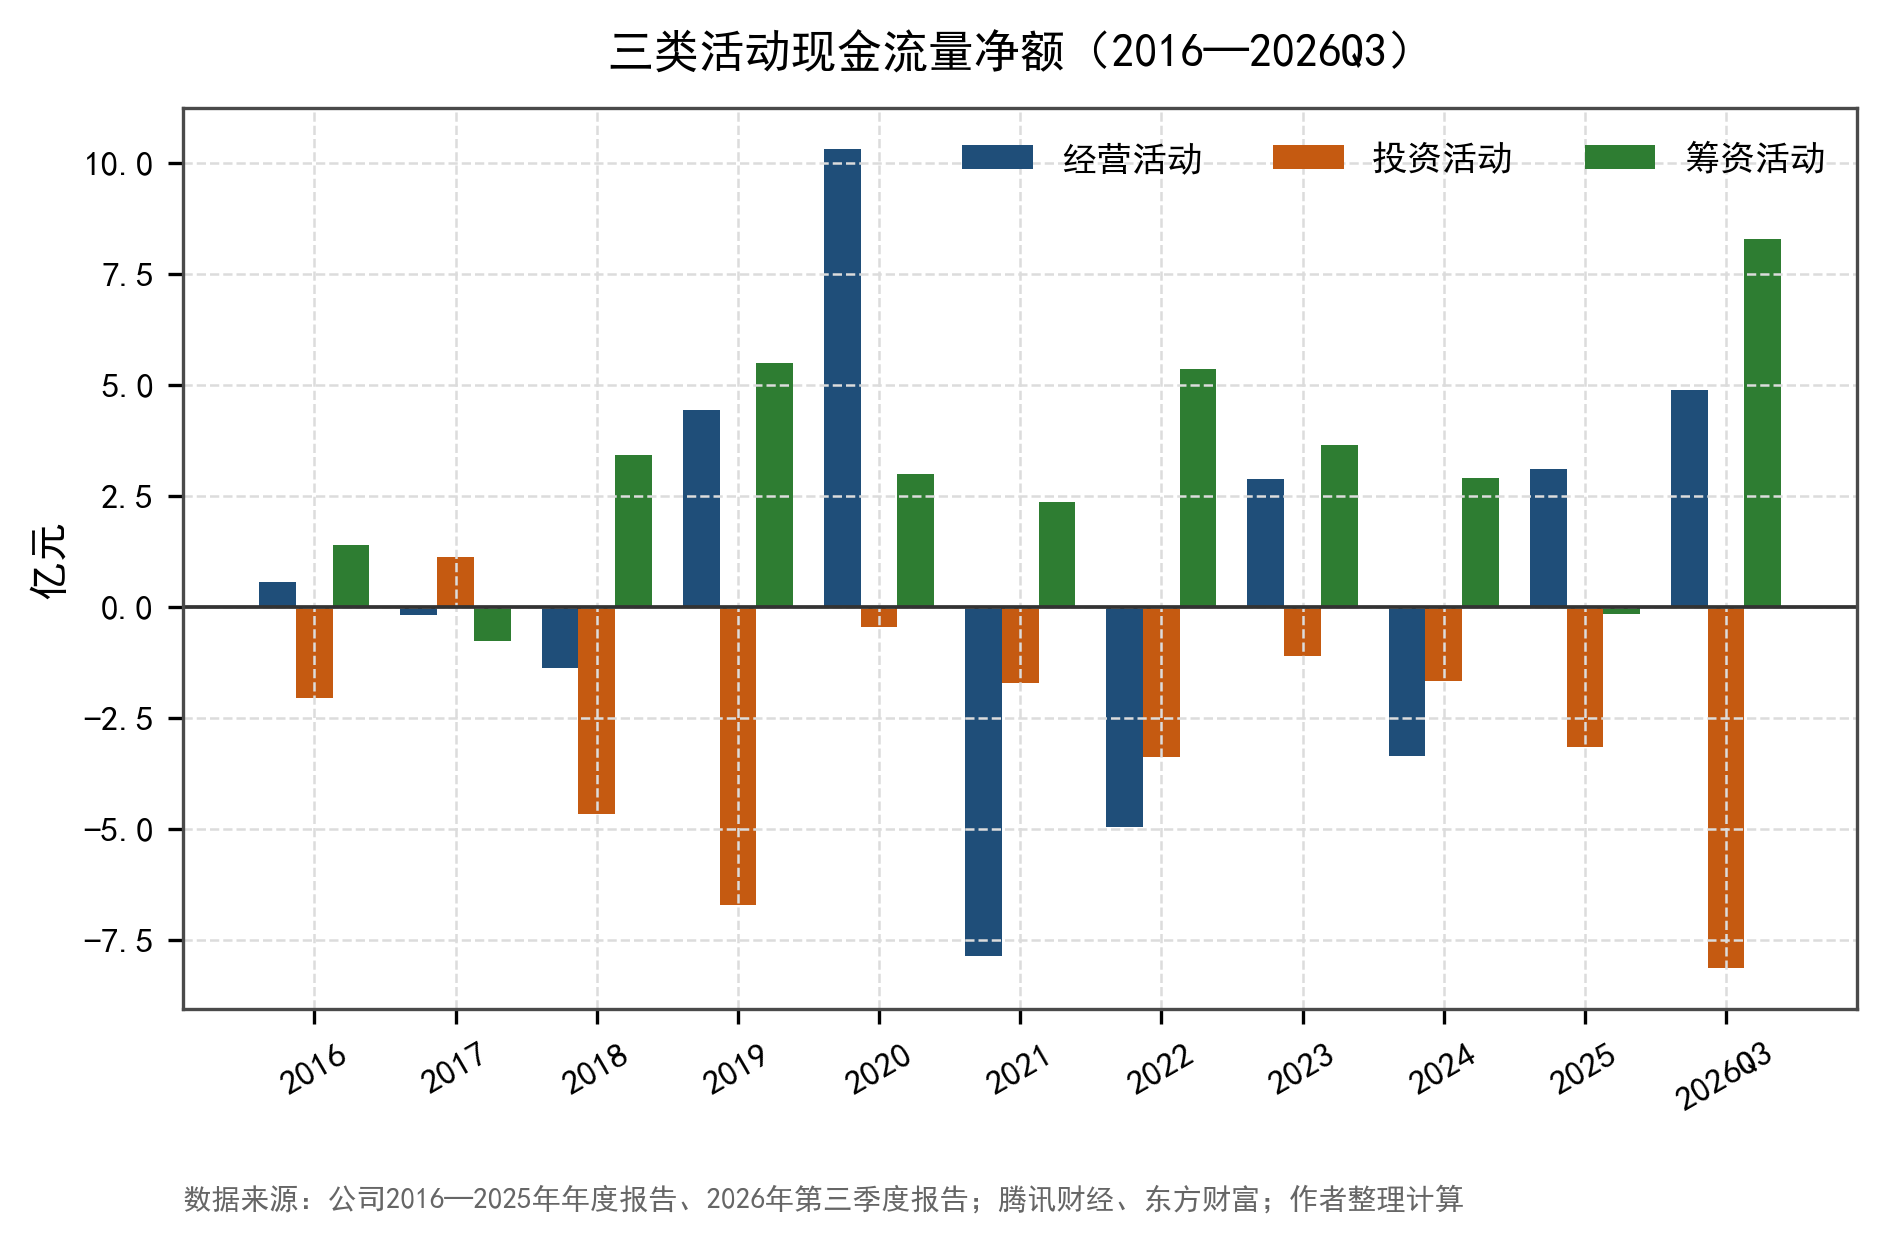

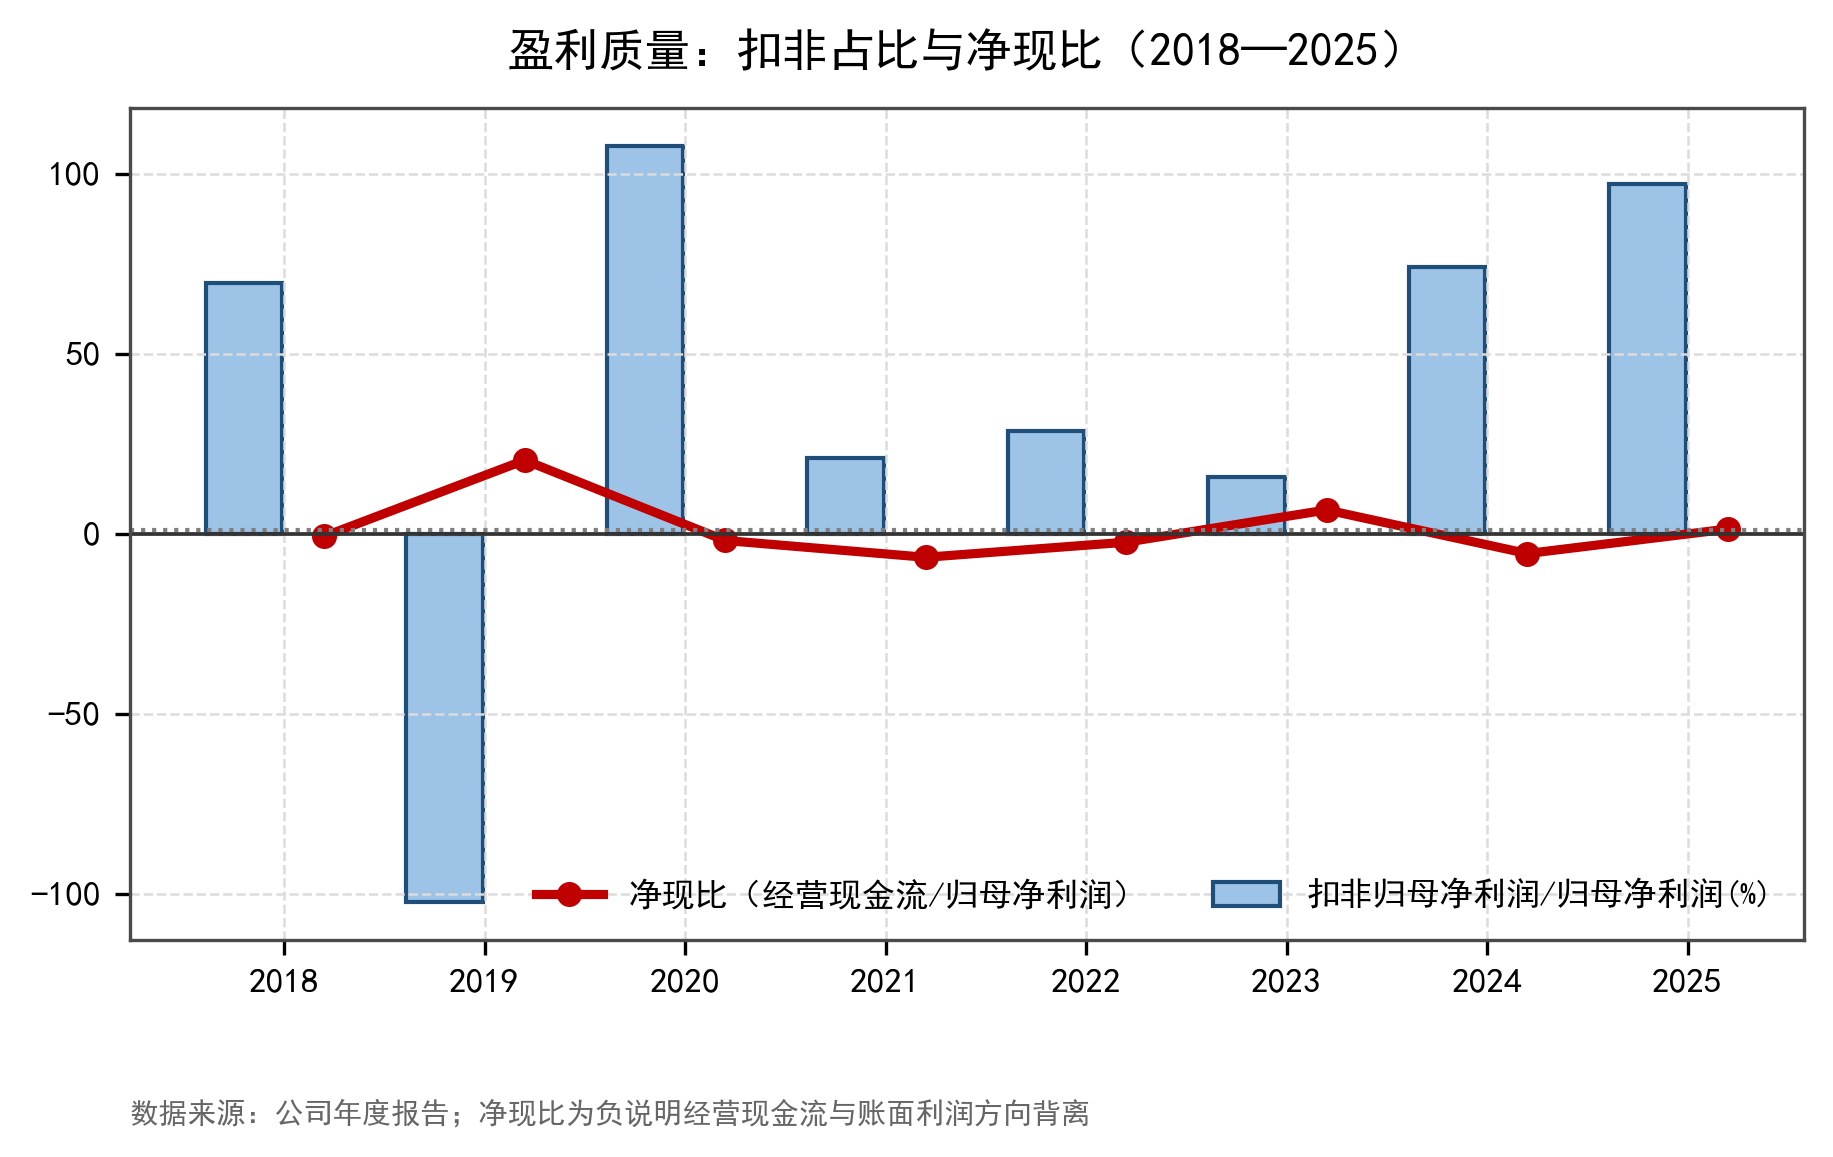

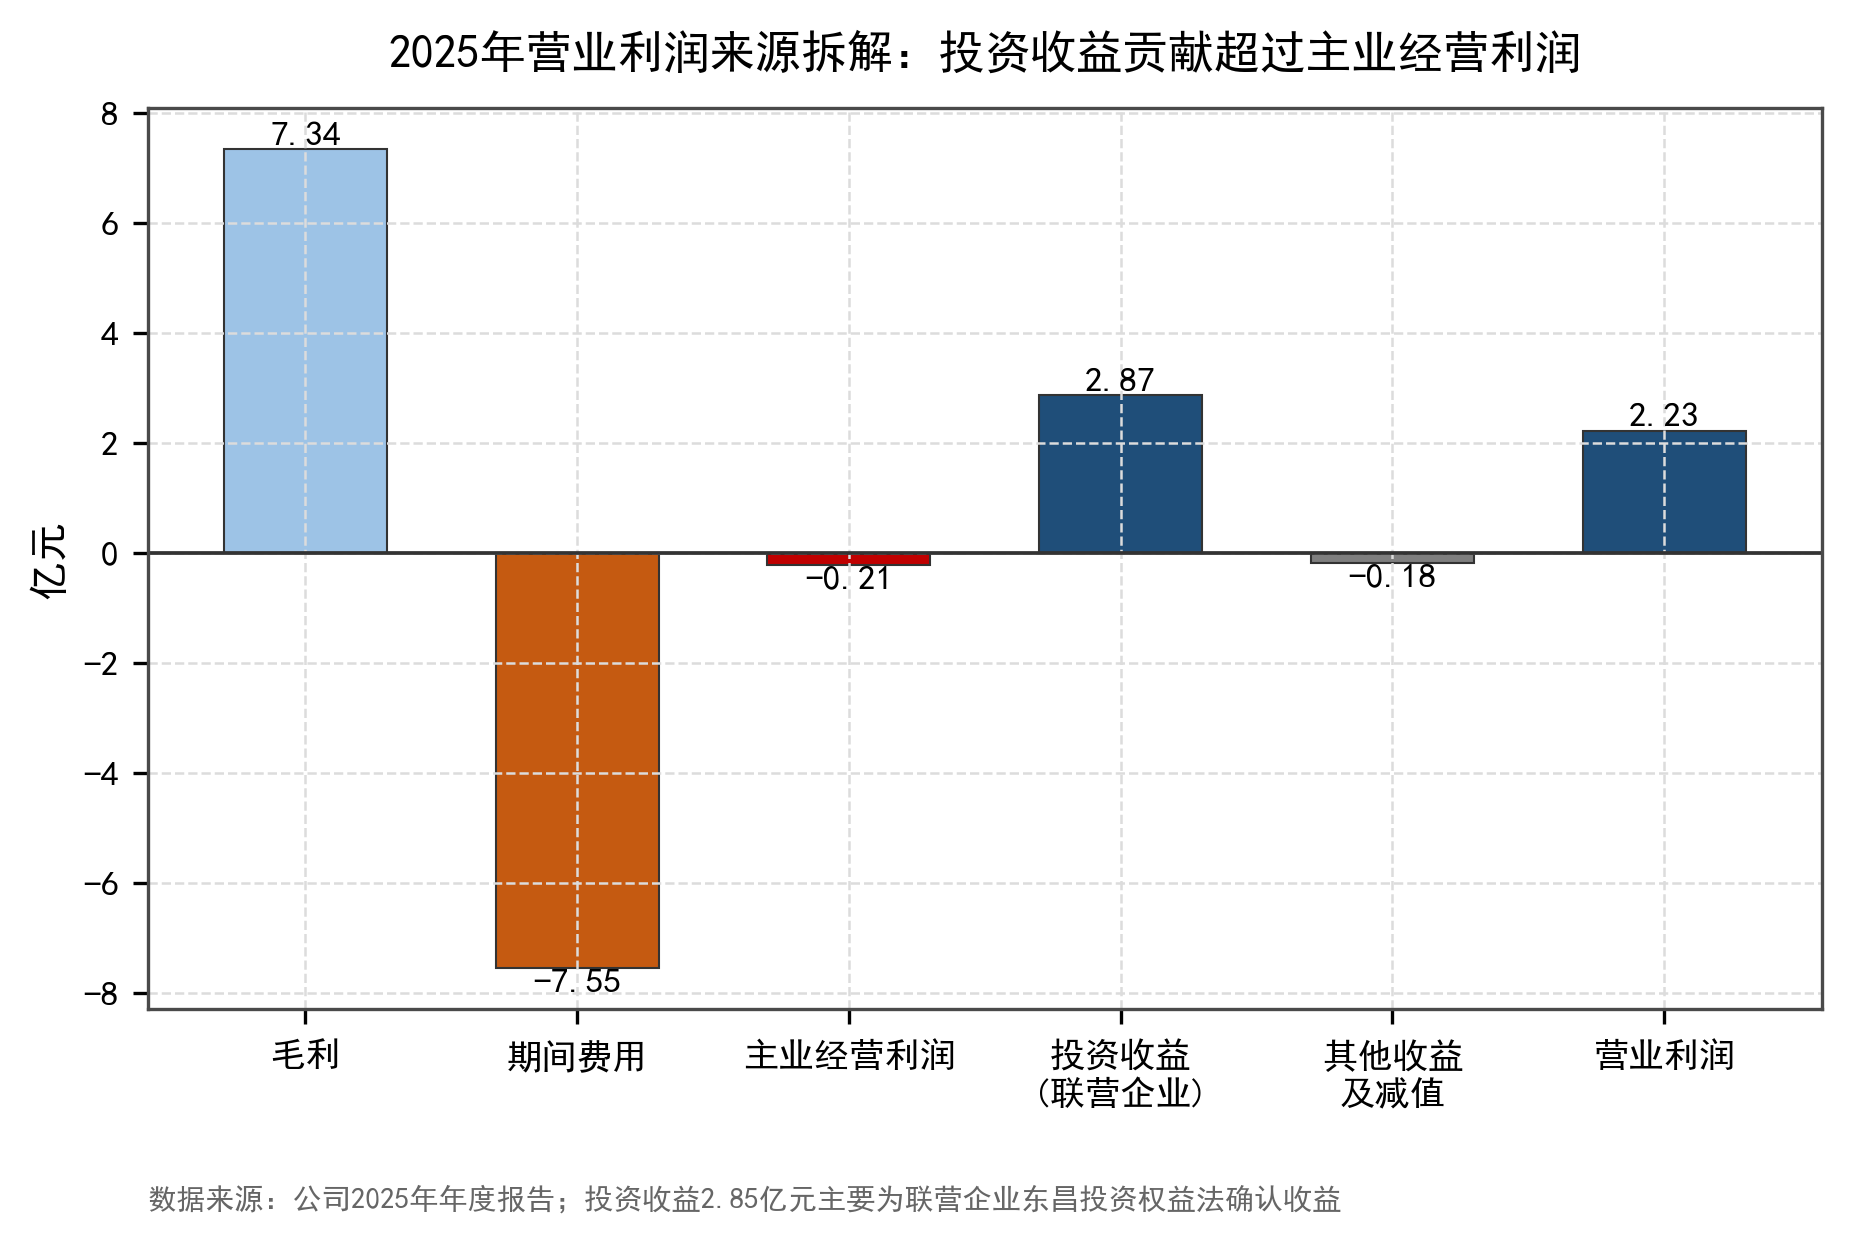

In [17]:
display(Image(filename=os.path.join(A.FIG, "图3-6_现金流量结构.png"), width=820))
display(Image(filename=os.path.join(A.FIG, "图3-7_盈利质量.png"), width=820))
display(Image(filename=os.path.join(A.FIG, "图3-8_2025利润拆解.png"), width=820))


In [18]:
# 2025 年利润桥：从毛利走到营业利润
s = d["single"]
y25 = s[s["年度"] == 2025]
rev = y25["营业收入"].sum(); cost = y25["营业成本"].sum()
gp = rev - cost
exp = sum(y25[c].sum() for c in ["销售费用", "管理费用", "研发费用", "财务费用"] if c in y25.columns)
inv = y25["投资收益"].sum(); oth = y25["其他收益"].sum()
print(f"2025 年营业收入      : {rev/1e8:8.2f} 亿元")
print(f"2025 年毛利          : {gp/1e8:8.2f} 亿元（毛利率 {gp/rev*100:.2f}%）")
print(f"2025 年期间费用      : {exp/1e8:8.2f} 亿元")
print(f"2025 年主业经营利润  : {(gp-exp)/1e8:8.2f} 亿元")
print(f"2025 年投资收益      : {inv/1e8:8.2f} 亿元")
print(f"2025 年归母净利润    : {d['ra'].set_index('年度').loc[2025,'归母净利润(亿元)']:.2f} 亿元")
print(f"2025 年扣非归母净利润: {d['ra'].set_index('年度').loc[2025,'扣非归母净利润(亿元)']:.2f} 亿元")


2025 年营业收入      :    52.87 亿元
2025 年毛利          :     7.34 亿元（毛利率 13.89%）
2025 年期间费用      :     7.55 亿元
2025 年主业经营利润  :    -0.21 亿元
2025 年投资收益      :     2.87 亿元
2025 年归母净利润    : 2.34 亿元
2025 年扣非归母净利润: 2.27 亿元


### 5.6 财务综合评价

| 维度 | 评价 | 关键依据 |
|---|---|---|
| 成长性 | 强（但需区分真假） | 2026 前三季度营收同比 +49.6%、归母同比 +125.8% |
| 盈利能力 | 显著改善，可持续性待验证 | 毛利率 28.72%，为十年最高，高毛利来自光通信结构性涨价 |
| 盈利质量 | 2026 年优，2025 年差 | 扣非占比 99.66% vs 2025 年靠投资收益，且 Q4 单季亏损 0.95 亿元 |
| 偿债能力 | 偏弱且持续恶化 | 资产负债率 63.60%，速动比率 0.81 |
| 营运效率 | 有所改善但仍偏低 | 应收周转 2.42 次、存货 2.46 次（前三季度口径） |
| 现金流 | 改善中 | 2026 前三季度净现比 0.66，仍低于 1 |


## 六、同业对比：在产业链中处于什么位置

选取 6 家可比公司：长飞光纤（601869，光纤预制棒龙头）、亨通光电（600487，光缆+海缆）、
中天科技（600522，光缆+海缆+电力）、烽火通信（600498，系统设备）、
中际旭创（300308，光模块）、通鼎互联（002491，光缆二线）。

> 口径说明：东方财富同业接口不包含 600105 本身，本分析在 `A._peer_plus_yd()` 中把公司自身
> 按同一口径补入面板，否则会出现"同业对比图里没有主角"的问题。


In [19]:
peer25 = A.t_peer(d)
peer25 = peer25[peer25["报告期"] == "2025年报"]
yd = d["ra"].set_index("年度").loc[2025]
peer25 = pd.concat([peer25, pd.DataFrame([{
    "名称": "永鼎股份", "报告期": "2025年报",
    "营业收入(亿元)": yd["营业收入(亿元)"], "归母净利润(亿元)": yd["归母净利润(亿元)"],
    "毛利率%": yd["毛利率%"], "净利率%": yd["归母净利率%"],
    "加权ROE%": yd["ROE%"], "资产负债率%": yd["资产负债率%"],
    "EPS(元)": yd["EPS(元)"], "BPS(元)": yd["BPS(元)"],
}])], ignore_index=True)
print("表 6-1 2025 年同业公司主要指标对比")
print(peer25[["名称", "营业收入(亿元)", "归母净利润(亿元)", "毛利率%", "净利率%",
              "加权ROE%", "资产负债率%", "EPS(元)", "BPS(元)"]].round(2).to_string(index=False))


表 6-1 2025 年同业公司主要指标对比
    名称  营业收入(亿元)  归母净利润(亿元)  毛利率%  净利率%  加权ROE%  资产负债率%  EPS(元)  BPS(元)
长飞光纤          142.52              8.14    30.73     6.19      6.92        51.12     1.07    16.68
亨通光电          668.55             26.80    12.46     4.26      8.96        51.73     1.10    12.88
中天科技          525.00             29.02    13.88     5.59      8.00        38.11     0.86    10.99
烽火通信          249.19              4.36    21.10     1.51      3.14        59.49     0.36    12.91
中际旭创          382.40            107.97    42.04    30.28     43.84        30.18     9.80    26.79
通鼎互联           34.13             -0.76    19.45    -1.94     -3.05        53.34    -0.06     2.01
永鼎股份           52.87              2.34    13.89     4.42      7.45        61.89     0.16     2.17


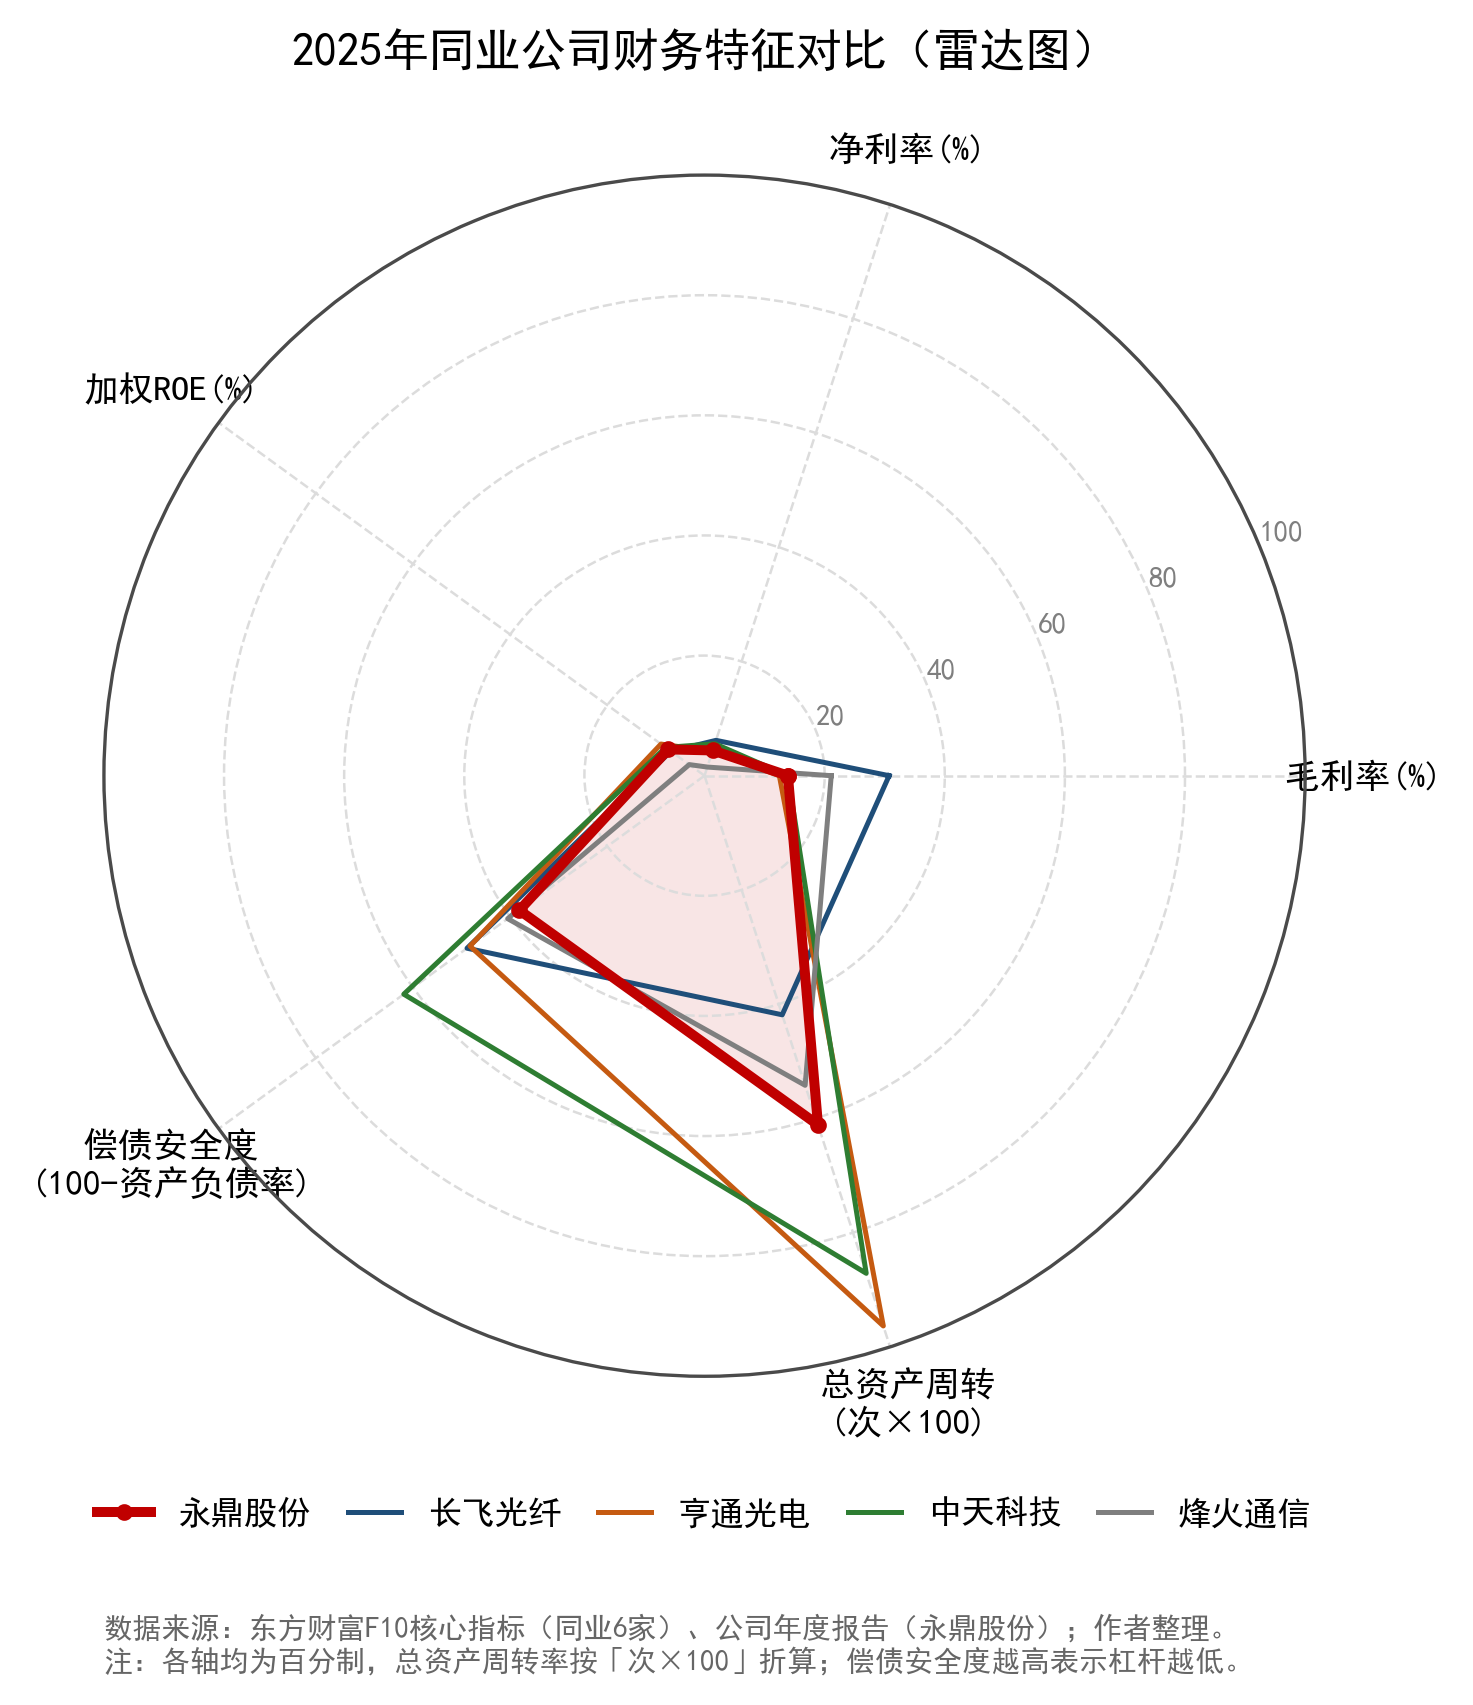

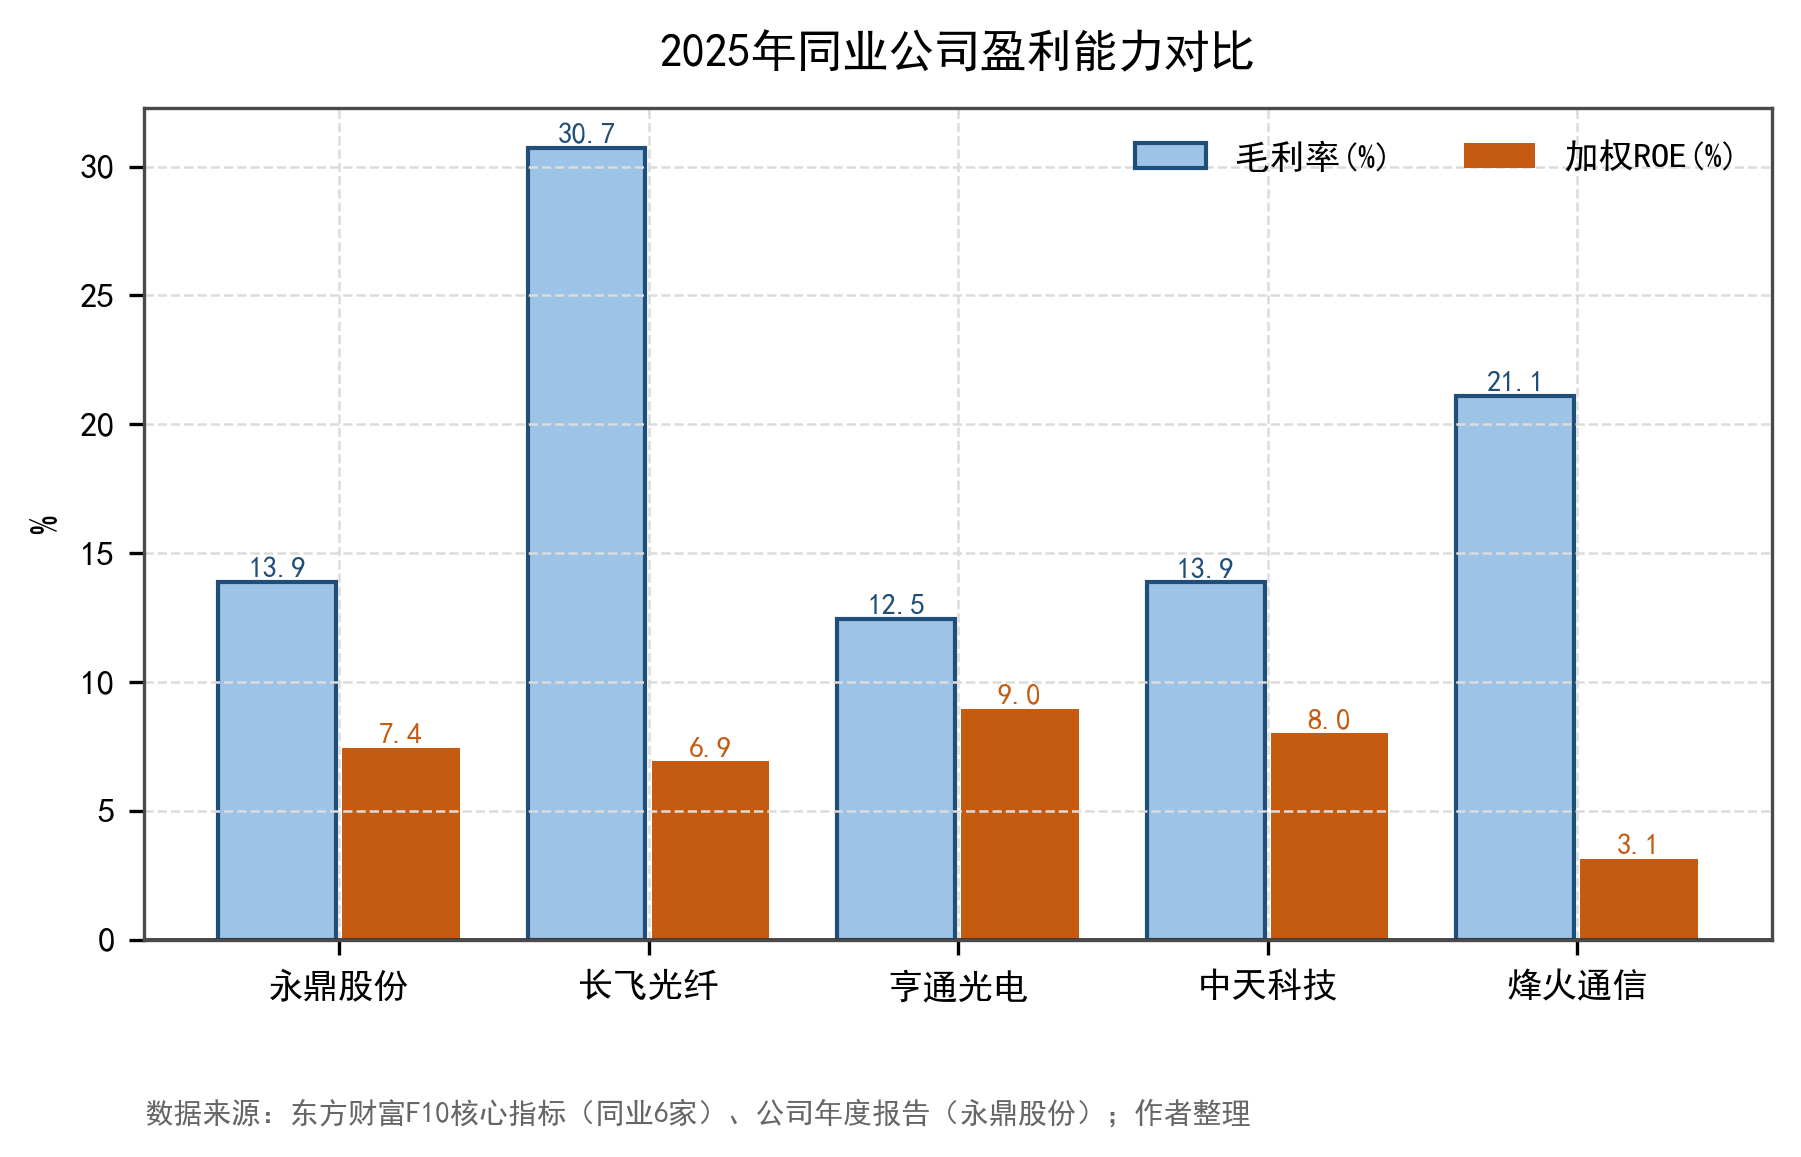

In [20]:
display(Image(filename=os.path.join(A.FIG, "图4-1_同业雷达图.png"), width=620))
display(Image(filename=os.path.join(A.FIG, "图4-2_同业盈利对比.png"), width=820))


雷达图给出的画像很清楚：

- **中际旭创**是"高毛利—高 ROE—低杠杆"的极致，2025 年净利率 30.28%、ROE 43.84%，
  代表 AI 算力链条上议价能力最强的一环；
- **长飞光纤**毛利率 30.73% 但 ROE 仅 6.92%，说明其资产重、周转慢、盈利尚未完全释放；
- **亨通、中天**是"规模大、毛利薄、周转快"的典型，靠体量与周转赚取回报；
- **烽火通信**毛利率 21.10% 但净利率仅 1.51%，费用侵蚀严重；
- **永鼎**处于"毛利率中等（13.89%）、ROE 中等（7.45%）、杠杆最高（61.89%）"的位置——
  即**用最高的杠杆，取得了中等的回报**，这是估值上应当折价而非溢价的理由。

但要注意，这张图用的是 2025 年数据，而 2026 年前三季度永鼎的毛利率已升至 28.72%，
若以 2026 年口径重画，永鼎在"毛利率"轴上的位置会接近长飞。
**同业对比的结论必须与最新经营数据结合看，否则会得出过时的判断。**


## 七、股票估值分析

### 7.1 估值基准

以 2026-10-27 收盘价 25.30 元计算，总股本 14.62 亿股，总市值 369.88 亿元；
TTM 归母净利润 6.47 亿元（2025Q4—2026Q3），TTM 营业收入 70.86 亿元。


In [21]:
print(A.t_valuation(d).to_string(index=False))

v = d["val"].dropna(subset=["PE_TTM"])
v = v[v["日期"] >= "2017-01-01"]
cur = d["val"].iloc[-1]
print("\n历史分位（2017 年以来，n = %d 个交易日）" % len(v))
items = [("PE(TTM)", "PE_TTM", v["PE_TTM"]),
         ("PB", "PB", d["val"].dropna(subset=["PB"])["PB"]),
         ("PS(TTM)", "PS_TTM", d["val"].dropna(subset=["PS_TTM"])["PS_TTM"])]
for lab, col, s in items:
    print(f"  {lab:10s} 当前 {cur[col]:6.2f} 倍，历史 {100 * (s <= cur[col]).mean():5.1f}% 分位")


               指标   数值                 说明
         收盘价(元)  25.30           2026-10-27
       总股本(亿股)  14.62         2026年三季报
       总市值(亿元) 369.88        收盘价×总股本
TTM归母净利润(亿元)   6.47        2025Q4—2026Q3
  TTM营业收入(亿元)  70.86        2025Q4—2026Q3
            PE(TTM)  57.13 总市值/TTM归母净利润
            PB(MRQ)   9.55    总市值/归母净资产
            PS(TTM)   5.22   总市值/TTM营业收入

历史分位（2017 年以来，n = 1900 个交易日）
  PE(TTM)    当前  57.13 倍，历史  60.2% 分位
  PB         当前   9.55 倍，历史  92.3% 分位
  PS(TTM)    当前   5.22 倍，历史  91.1% 分位


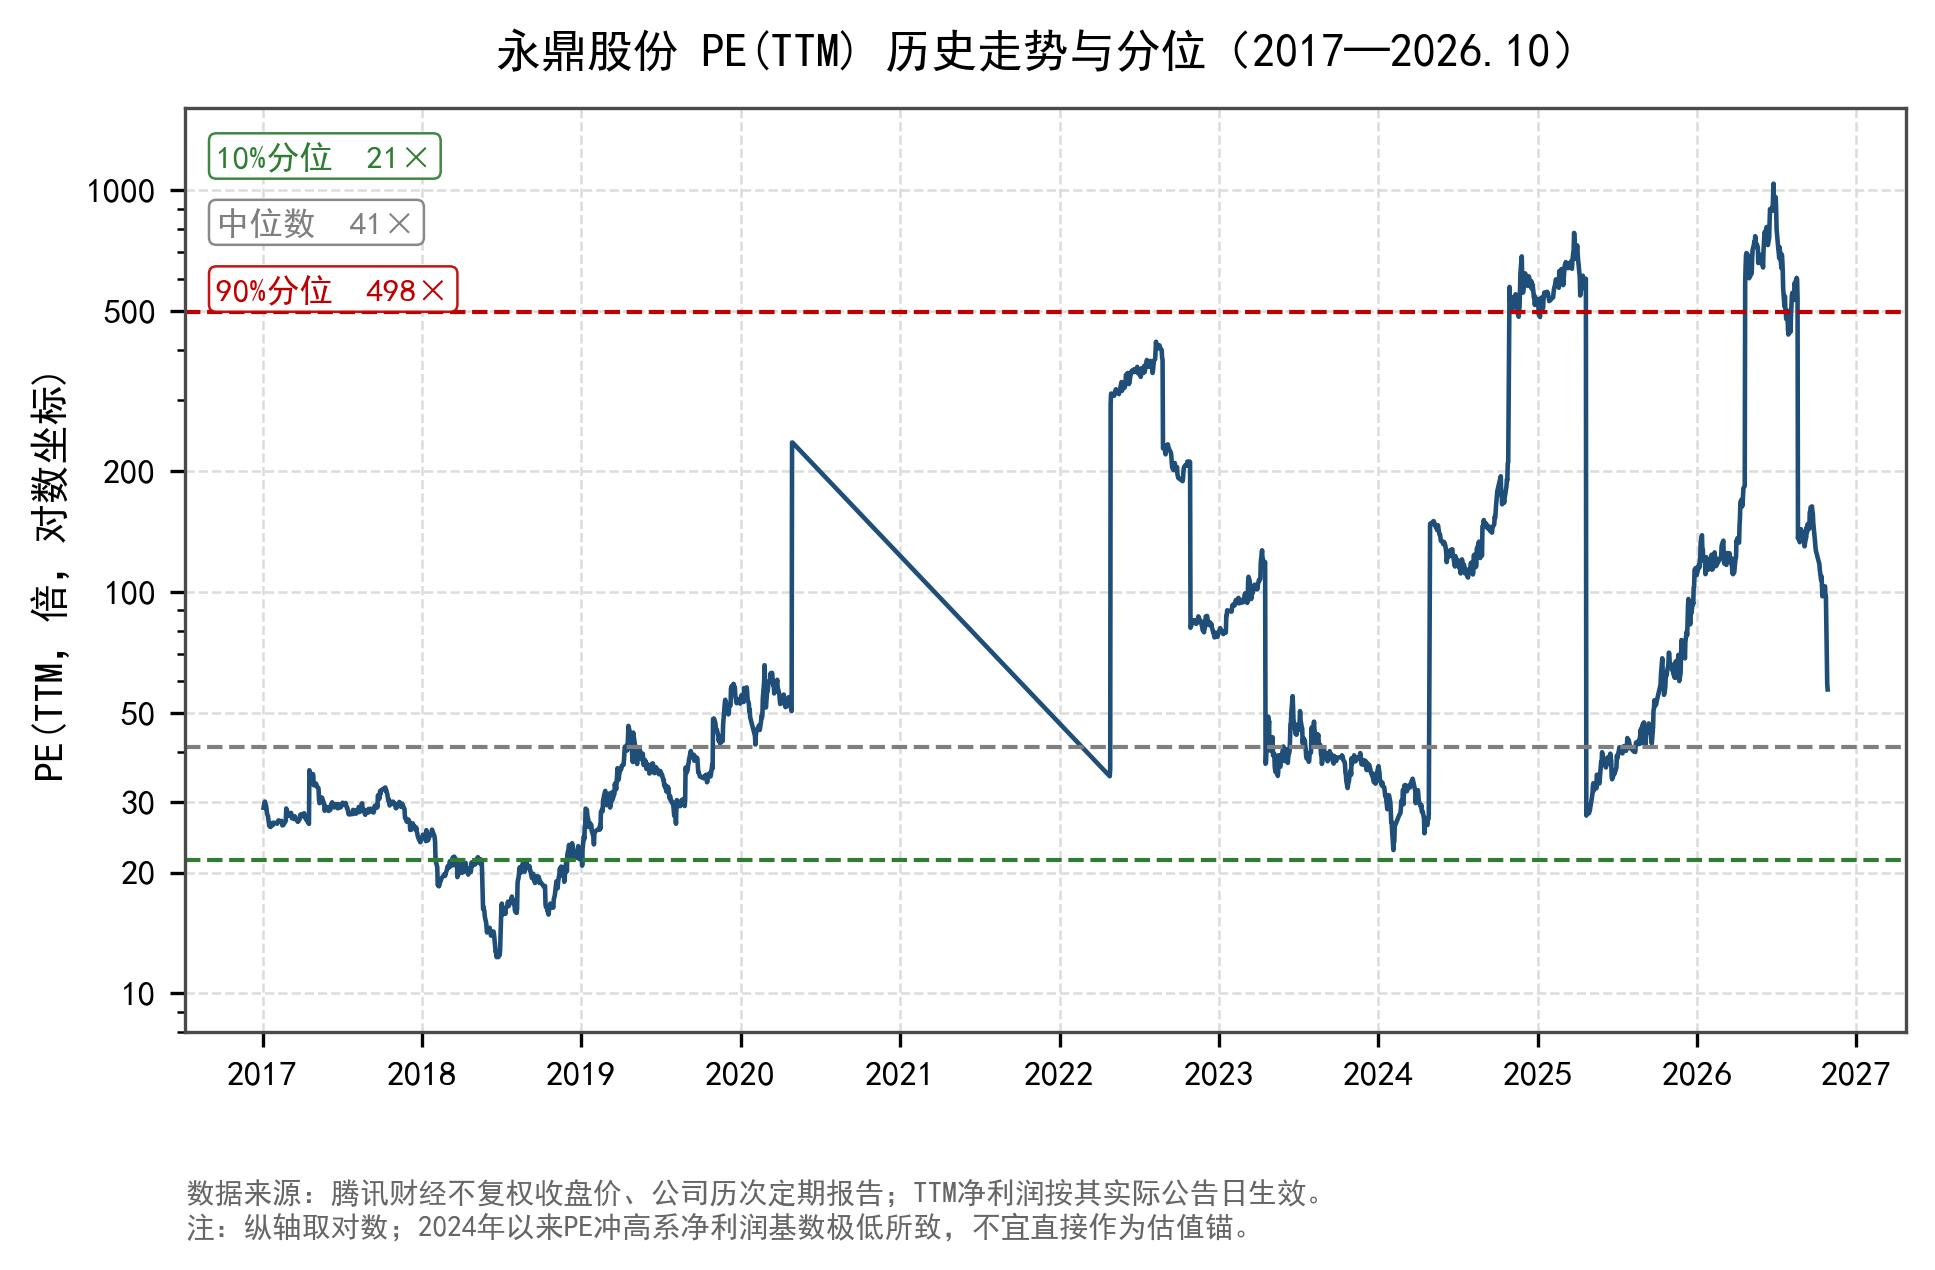

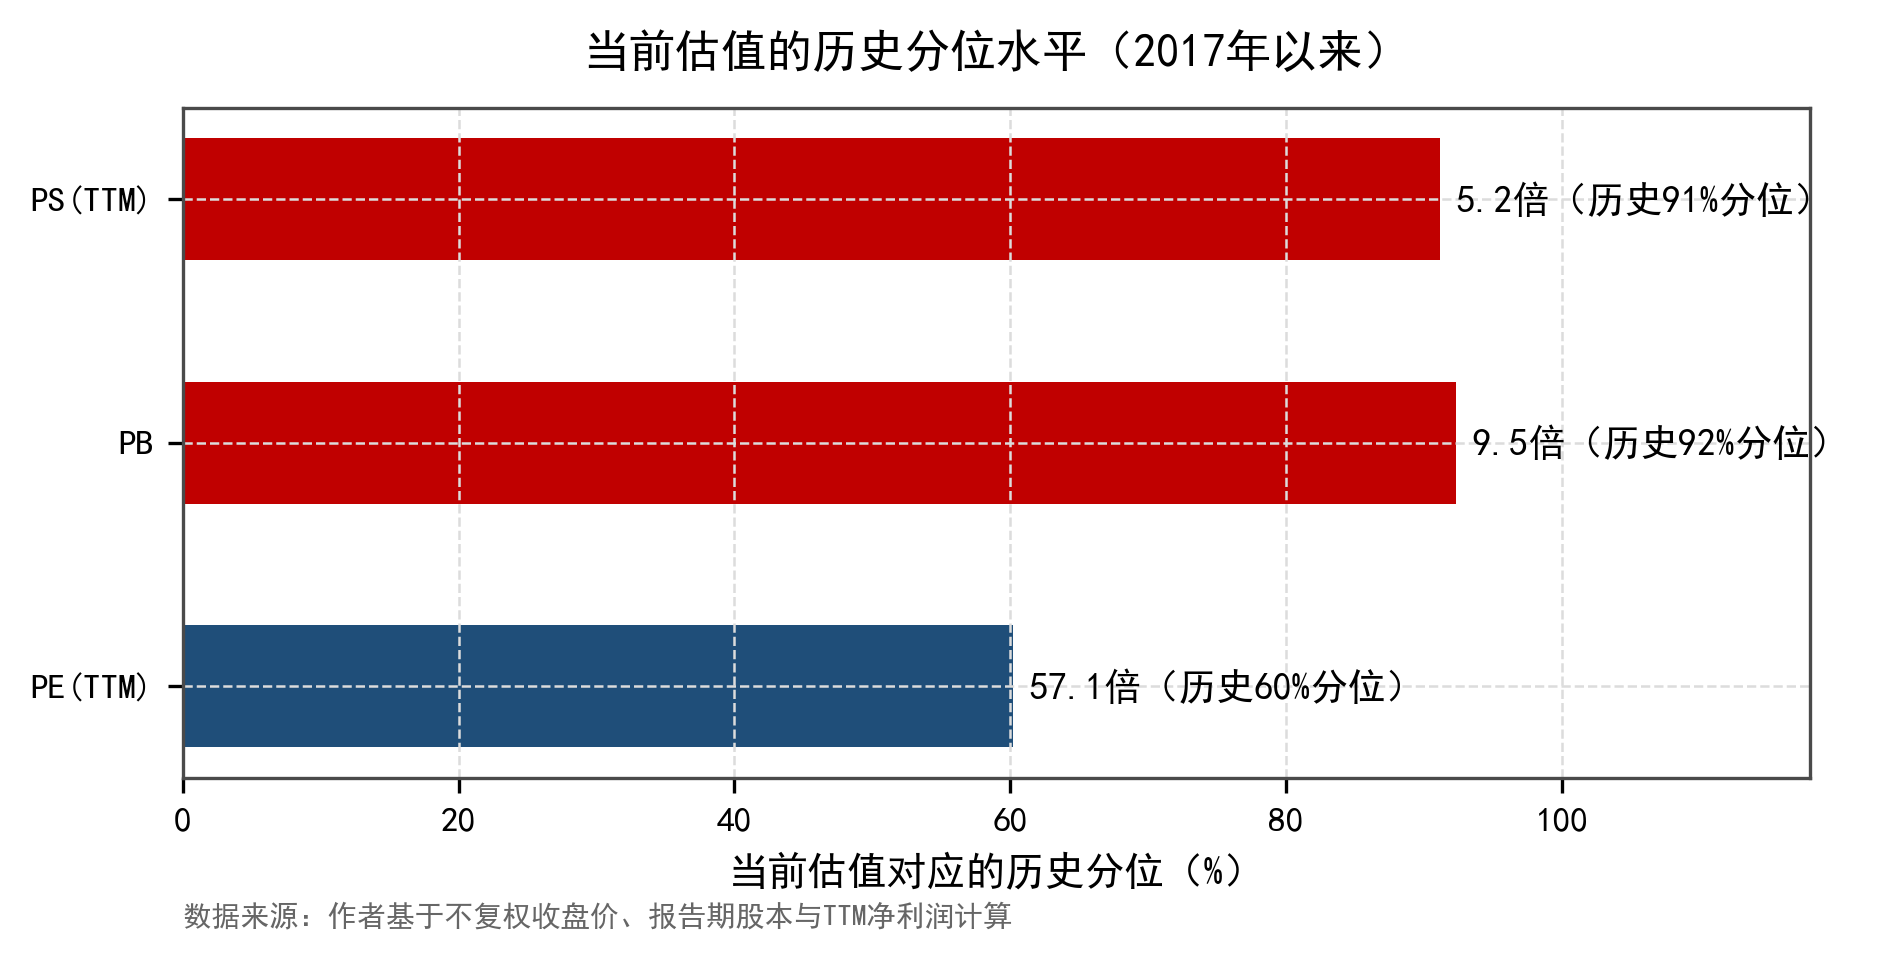

In [22]:
display(Image(filename=os.path.join(A.FIG, "图5-1_PE_Band.png"), width=820))
display(Image(filename=os.path.join(A.FIG, "图5-3_估值分位.png"), width=760))


### 7.2 相对估值：PE 失真，PB 与 PS 更能说明问题

当前 PE(TTM) 57.1 倍、PB 9.55 倍、PS(TTM) 5.22 倍。三者的历史分位差异很大，
这个差异本身就是结论的一部分：

| 指标 | 当前值 | 历史分位（2017 年以来） | 判读 |
|---|---|---|---|
| PE(TTM) | 57.1 倍 | **60.2%** | 高于中位数（41 倍）约 39%，但并不极端 |
| PB(MRQ) | 9.55 倍 | **92.3%** | 显著偏贵 |
| PS(TTM) | 5.22 倍 | **91.1%** | 显著偏贵 |

**为什么 PE 分位只有 60%？** 因为 2019—2024 年公司净利润长期在 0.2—2 亿元的低位徘徊，
PE 被分母"除小"抬到数百倍甚至近千倍（图 5-1 中的尖峰），把整个分布的上沿拉得极高。
在这样的样本里，即使 57 倍也排不进前 10%。这说明**PE 分位法在盈利极不稳定的公司身上会失效**：
它把"利润塌陷"误读成"估值便宜"。

剔除归母净利润低于 1 亿元的年份后再算，当前 PE 位于 67.0% 分位，与表内判断一致——
**贵，但不是历史最贵**。

相比之下，PB 与 PS 的分母（净资产、营业收入）十年间相对稳定，不受利润塌陷干扰，
因此 92%、91% 的分位更可信。**PB 9.55 倍意味着市场为公司每 1 元净资产支付 9.55 元**，
而 2017—2025 年的 PB 中位数仅约 2.2 倍。


In [23]:
# 剔除低利润年份后的 PE 分位（分母质量修正）
ra = d["ra"].set_index("年度")
ok_years = ra[ra["归母净利润(亿元)"] >= 1.0].index.tolist()
vv = v[v["日期"].dt.year.isin(ok_years)]
print("归母净利润 ≥ 1 亿元的年份：", ok_years)
print("这些年份的 PE(TTM)：中位数 %.1f 倍，10%%分位 %.1f 倍，90%%分位 %.1f 倍，最大值 %.1f 倍"
      % (vv["PE_TTM"].median(), vv["PE_TTM"].quantile(.1), vv["PE_TTM"].quantile(.9), vv["PE_TTM"].max()))
print("当前 PE 在这些年份中的分位：%.1f%%" % (100 * (vv["PE_TTM"] <= cur["PE_TTM"]).mean()))


归母净利润 ≥ 1 亿元的年份： [2015, 2016, 2017, 2018, 2021, 2022, 2025]
这些年份的 PE(TTM)：中位数 29.8 倍，10%分位 19.1 倍，90%分位 374.0 倍，最大值 783.2 倍
当前 PE 在这些年份中的分位：67.0%


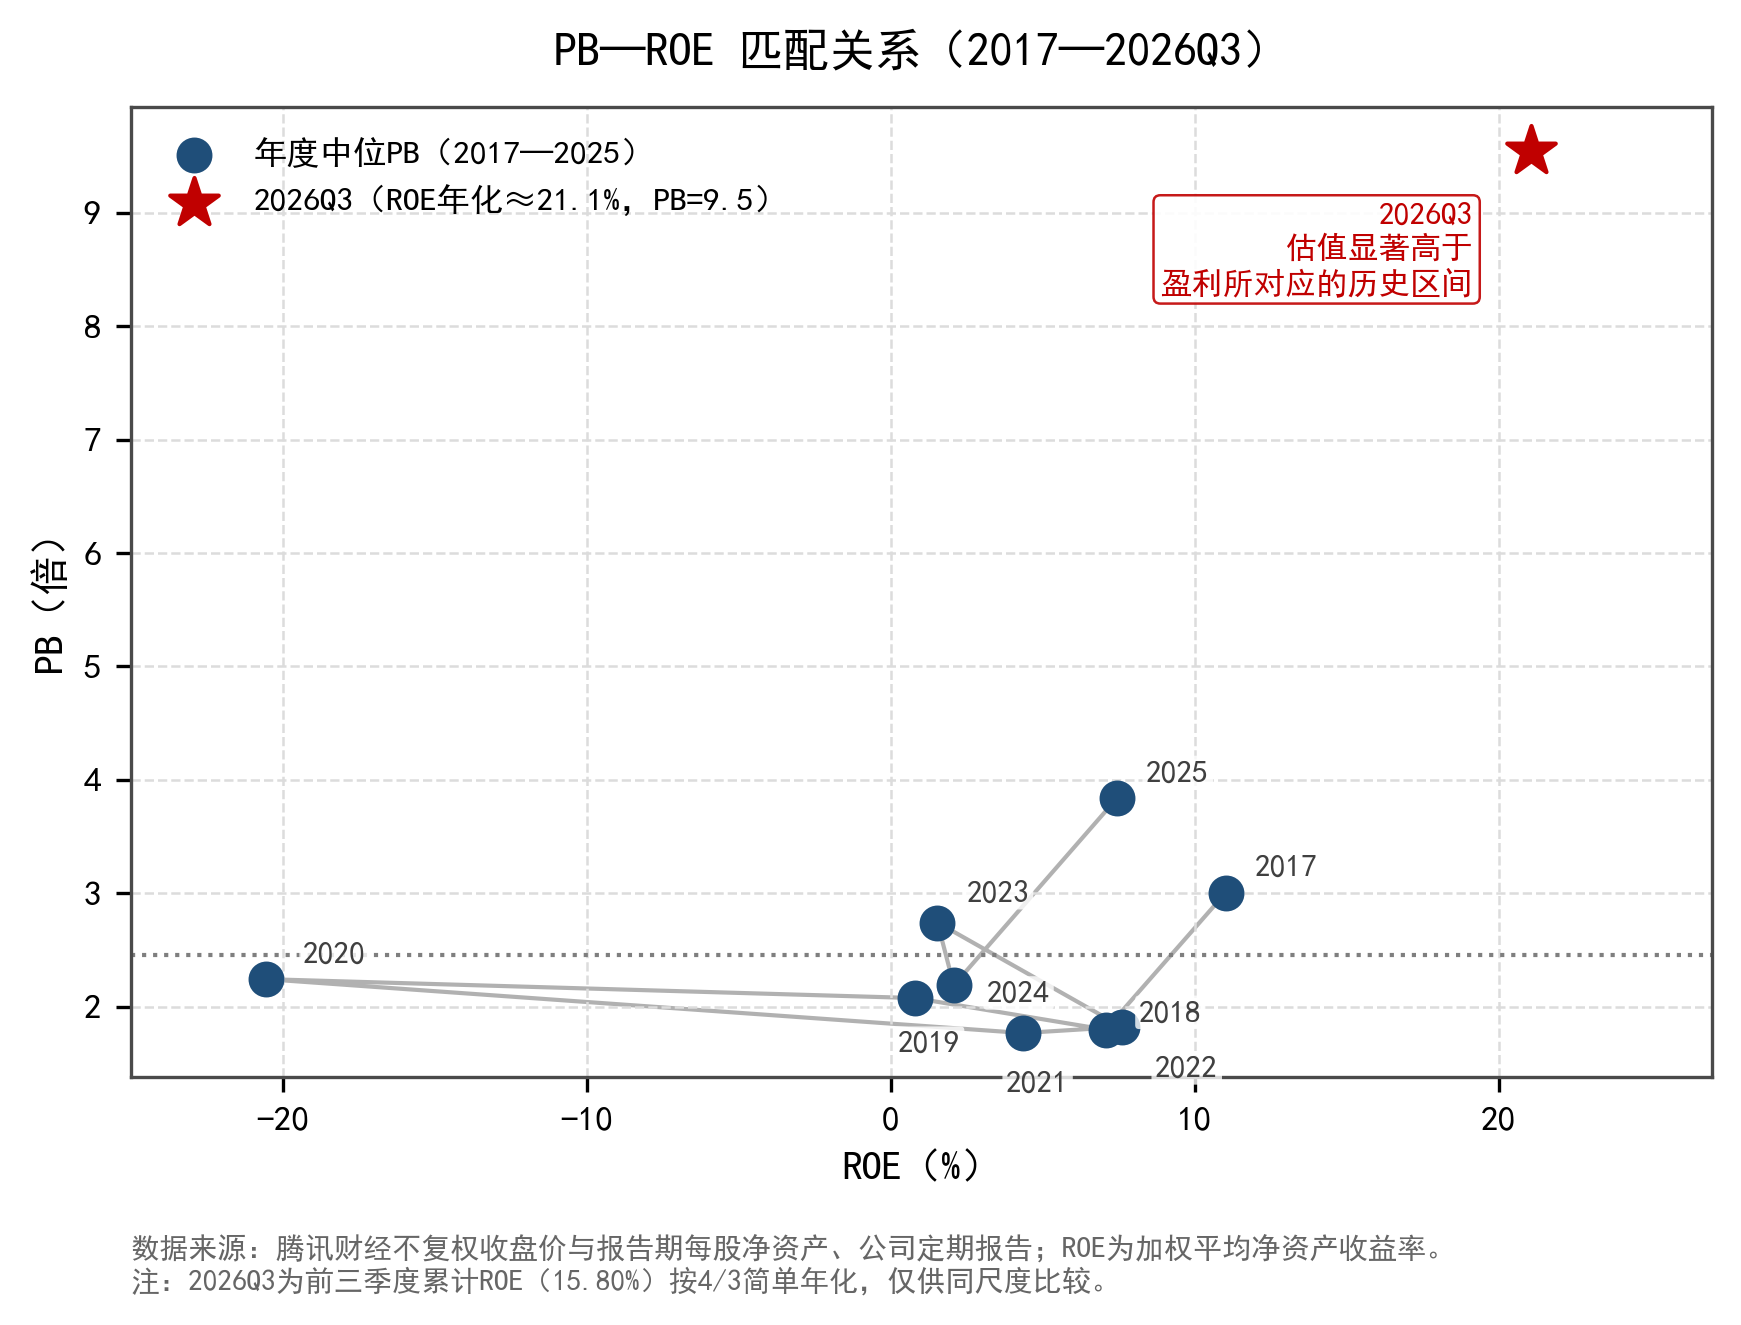

In [24]:
display(Image(filename=os.path.join(A.FIG, "图5-2_PB_ROE.png"), width=780))


PB—ROE 图揭示了估值的核心矛盾：2017—2025 年，公司的 PB 与 ROE 基本落在一条
"ROE 每提升 1 个百分点、PB 提升约 0.2 倍"的经验线上；而 2026Q3 的点（ROE 年化 21.1%、PB 9.5）
**远高于这条线**——市场给的估值，已经超出了当期盈利所能解释的范围，
隐含的是对 2027—2028 年光通信高景气的持续预期。


### 7.3 绝对估值：DCF 敏感性

以 2026 年自由现金流约 6.0 亿元为基期（2026 前三季度经营现金流净额约 4.9 亿元，
全年约 6.5 亿元，扣除维持性资本开支后取 6.0 亿元），2027—2030 年增速取两组假设：

- **中性情形**：30% / 18% / 10% / 6%，WACC 9%—11%，g 2%—3% → 企业价值 **109—161 亿元**；
- **乐观情形**：50% / 35% / 20% / 10% → 企业价值 **159—236 亿元**。

扣除净有息负债（有息负债 41.73 亿元 − 货币资金 21.01 亿元 ≈ **20.7 亿元**）后，
对应股权价值约 **88—215 亿元**，而当前市值为 **369.88 亿元**。
反解一下：在 WACC 10%、永续增长 3% 的假设下，要支撑当前市值，需要未来四年
自由现金流**复合增速达到 55% 以上**——这是一个只有在"光通信订单持续超预期 + 高毛利长期维持"
同时成立时才能实现的路径。

因此 DCF 在本案例中的作用不是"算出精确的内在价值"，而是**检验当前市值隐含了多高的增长假设**。


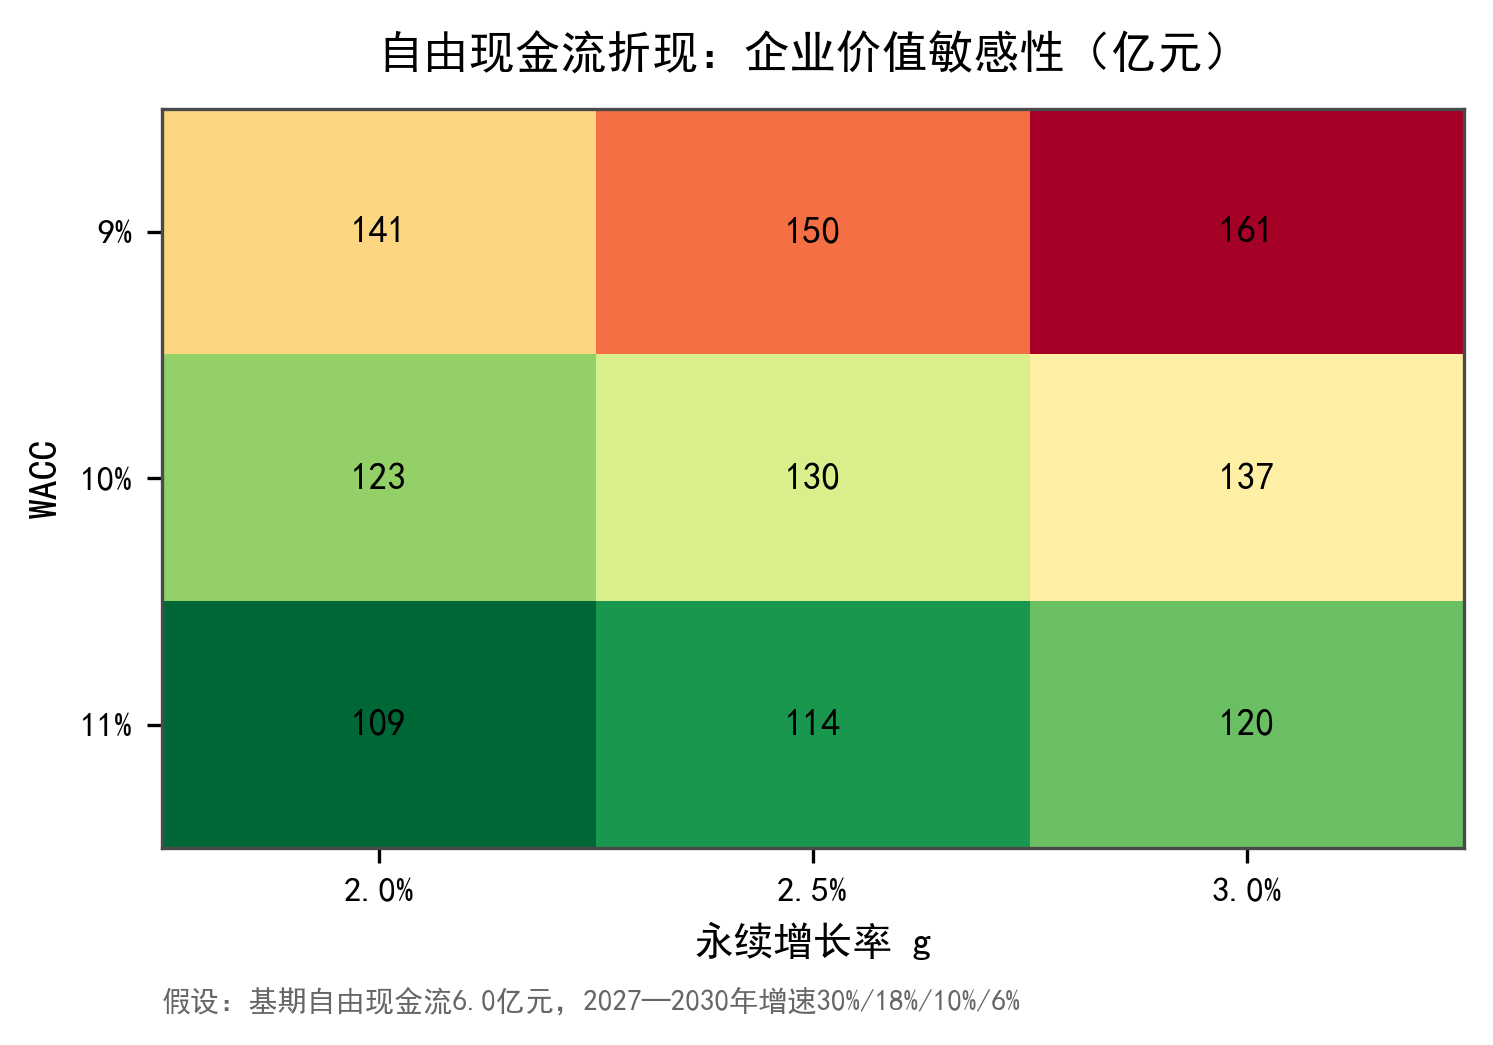

In [25]:
display(Image(filename=os.path.join(A.FIG, "图5-4_DCF敏感性.png"), width=620))


### 7.4 估值结论

| 方法 | 结果 | 对当前市值的含义 |
|---|---|---|
| PE 分位 | 57.1 倍，60.2% 分位（剔除低利润年份 67.0%） | 高于中枢但不极端 |
| PB 分位 | 9.55 倍，92.3% 分位（历史中位 2.2 倍） | 显著高估 |
| PS 分位 | 5.22 倍，91.1% 分位 | 显著高估 |
| PB—ROE 匹配 | PB 9.5 倍显著高于 ROE 所对应的经验水平 | 高估 |
| DCF（中性／乐观） | 股权价值 88—215 亿元 | 高估 42%—76% |

**除 PE 因分母极不稳定而参考价值有限外，其余四个角度一致指向"估值已充分反映甚至透支
2026—2027 年业绩预期"。**


## 八、投资价值综合结论与风险提示

### 8.1 六维评分

按成长性、盈利能力、盈利质量、偿债安全、营运效率、估值吸引力六个维度打分（满分 100）：


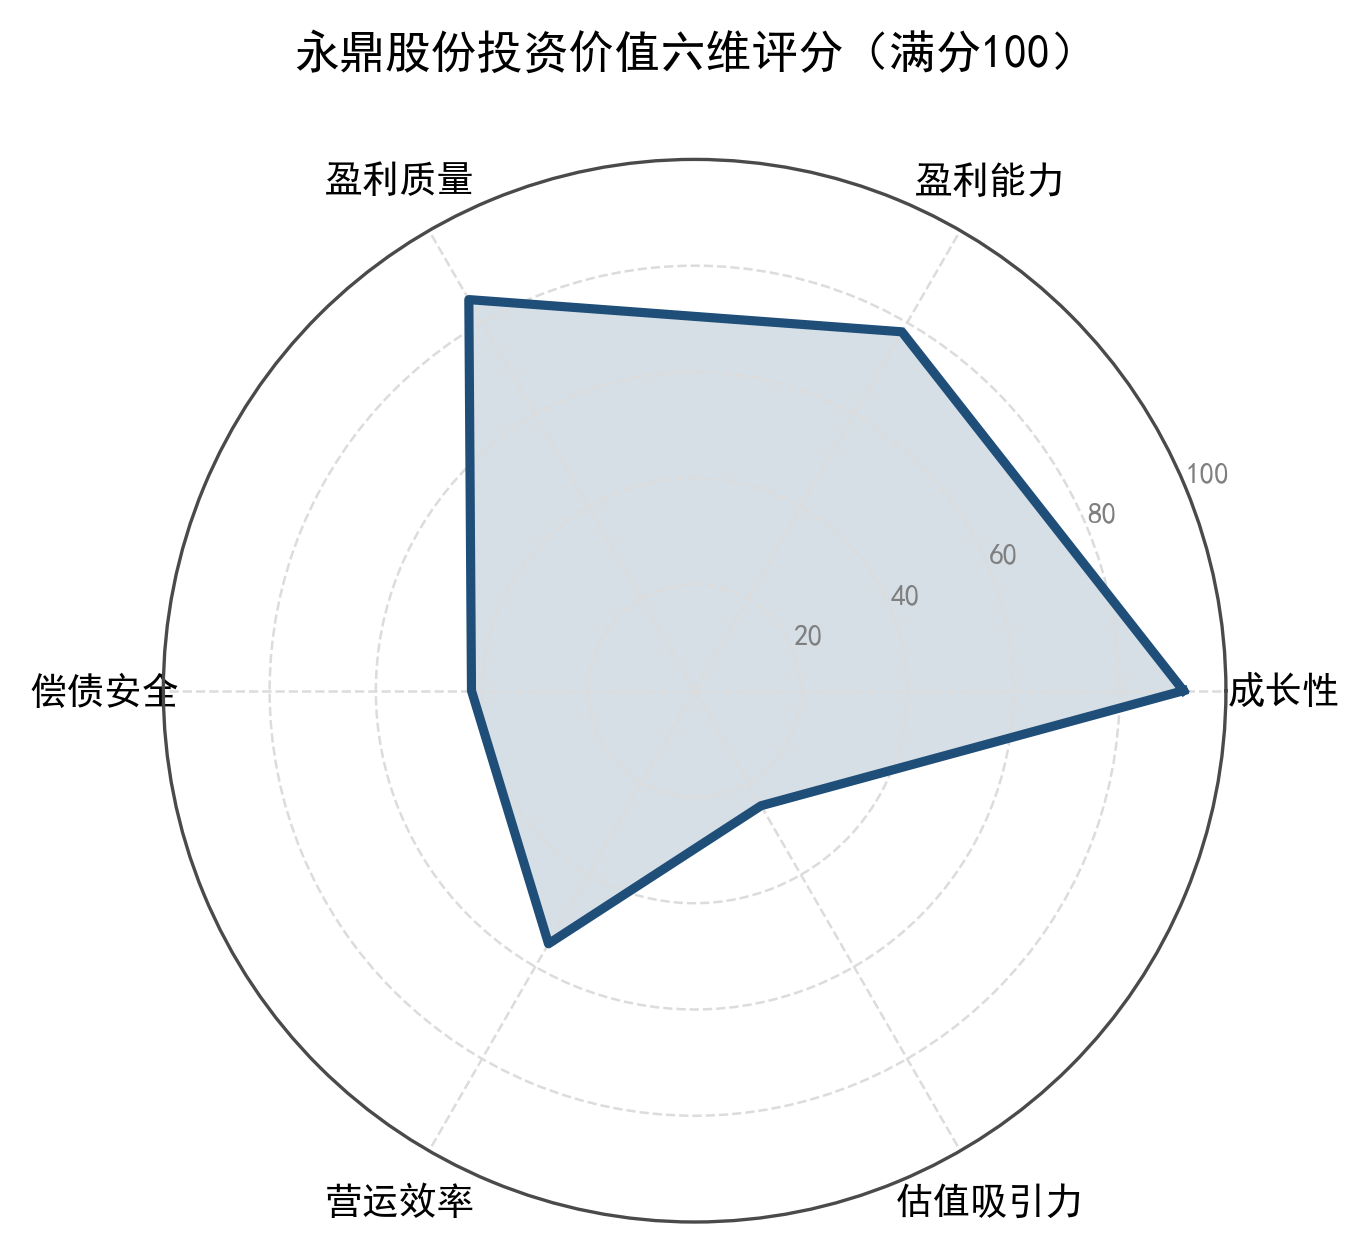

In [26]:
display(Image(filename=os.path.join(A.FIG, "图5-5_综合评分.png"), width=560))


### 8.2 结论：**谨慎看待（基本面改善明确，但估值已透支）**

**支持"看好"的理由：**
1. 2026 年前三季度扣非归母 7.40 亿元、扣非占比 99.66%，是十年来第一次由主业驱动的真实盈利；
2. 光通信毛利率 58.5%（2026H1），验证了公司在 AI 算力链条中拿到了高附加值订单；
3. 行业景气度向上（AI 数据中心、海风、电网投资），赛道本身没有逆风。

**支持"谨慎"的理由：**
1. PB 处于 2017 年以来的 92.3% 分位（9.55 倍，历史中位 2.2 倍），PS 处于 91.1% 分位；
2. DCF 在"中性—乐观"假设下的股权价值（88—215 亿元）明显低于当前市值（369.88 亿元），
   反解需要未来四年自由现金流复合增速 55% 以上；
3. 资产负债率 63.60%、速动比率 0.81，杠杆已处历史高位，财务弹性有限；
4. 历史盈利记录不稳定：2016—2025 十年中有 4 年扣非归母净利润低于 0.3 亿元
   （2019、2020、2021、2023），2025 年利润还高度依赖一次性投资收益；
5. 光通信高毛利能否延续，取决于 AI 资本开支周期，存在明显的外部不确定性。

### 8.3 风险提示

| 风险类别 | 具体表现 | 影响 |
|---|---|---|
| 估值风险 | PE 57 倍、PB 9.5 倍，均处历史高位 | 业绩不及预期时股价回撤空间大 |
| 行业周期风险 | AI 算力资本开支若放缓，光纤光缆溢价将快速收窄 | 毛利率可能从 28.72% 回落至 15% 附近 |
| 财务风险 | 有息负债约 46 亿元，财务费用同比 +48.14% | 利率或汇率波动直接侵蚀利润 |
| 客户集中风险 | 前五名客户占比 48.88% | 单一大客户流失将显著影响收入 |
| 海外经营风险 | EPC 项目回款周期长、结算货币多元 | 应收账款与汇兑损失 |
| 商誉与减值风险 | 历史上有商誉减值记录（2020 年） | 并购标的业绩不达预期时再度计提 |

### 8.4 投资建议

- **尚未持仓者**：不建议在当前价位追高。可等待两种情形之一出现再考虑配置：
  ①股价回调至 PB 6 倍以下（对应约 16 元）；②2026 年报确认光通信毛利率维持在 25% 以上
  且经营现金流净额/净利润 > 1。
- **已持仓者**：可继续持有并设置止盈线，重点跟踪季度毛利率与在手订单，一旦单季毛利率
  跌破 20%，应视为景气拐点信号。
- **观察指标**：①单季毛利率；②应收账款周转天数；③有息负债/EBITDA；④AI 相关订单公告。

> **一句话结论**：永鼎股份在 2026 年完成了从"周期制造"向"AI 算力受益者"的叙事切换，
> 基本面改善是真实的；但当前 369.88 亿元的市值已经把 2027 年的乐观情形提前兑现，
> 属于"好公司、贵价格"，**建议谨慎看待、等待更好的价格**。


In [27]:
# 关键结论数字汇总（供报告引用核对）
ra = d["ra"].set_index("年度")
q3 = d["q3"]
print("=" * 62)
print("关键结论数字一览")
print("=" * 62)
print(f"2025 营业收入 / 归母 / 扣非 : {ra.loc[2025,'营业收入(亿元)']:.2f} / "
      f"{ra.loc[2025,'归母净利润(亿元)']:.2f} / {ra.loc[2025,'扣非归母净利润(亿元)']:.2f} 亿元")
print(f"2026Q1-Q3 营业收入 / 归母     : {q3['营业收入(亿元)']:.2f} / {q3['归母净利润(亿元)']:.2f} 亿元")
print(f"2026Q1-Q3 毛利率 / 净利率     : {q3['毛利率%']:.2f}% / {q3['归母净利率%']:.2f}%")
print(f"2026Q1-Q3 扣非占比            : {q3['扣非占比%']:.2f}%")
print(f"2026Q3 资产负债率 / 速动比率  : {q3['资产负债率%']:.2f}% / {q3['速动比率']:.2f}")
print(f"当前 PE(TTM) / PB / PS(TTM)   : {val['PE(TTM)']:.2f} / {val['PB(MRQ)']:.2f} / {val['PS(TTM)']:.2f}")
print(f"当前总市值                    : {val['总市值(亿元)']:.2f} 亿元")
print("=" * 62)


关键结论数字一览
2025 营业收入 / 归母 / 扣非 : 52.87 / 2.34 / 2.27 亿元
2026Q1-Q3 营业收入 / 归母     : 54.30 / 7.43 亿元
2026Q1-Q3 毛利率 / 净利率     : 28.72% / 13.68%
2026Q1-Q3 扣非占比            : 99.66%
2026Q3 资产负债率 / 速动比率  : 63.60% / 0.81
当前 PE(TTM) / PB / PS(TTM)   : 57.13 / 9.55 / 5.22
当前总市值                    : 369.88 亿元


---

### 附：本 Notebook 的运行说明

- 运行目录：项目根目录（`永鼎股份600105.SH投资分析/`）；
- 依赖：`pandas`、`numpy`、`matplotlib`、`python-docx`、`PyMuPDF`；
- 全部图表由 `scripts/analysis_lib.py` 生成，本 Notebook 只负责读取与展示，不重复绘图，
  以保证 Notebook 与 Word 报告使用**完全相同的图形文件**；
- 数据字典与抓取日志见 `data/README.md`。
